# 2.10 · Loss functions and optimisation: what a fitting program minimises, and how it walks downhill

Every inversion code and every neural-network library (the flexible fitted functions of Topic 3) minimises a number
called the loss. This notebook shows that a
loss is a negative log posterior in disguise (so choosing a loss means choosing a noise model and a prior), how the
standard optimisers walk downhill on a real nonlinear forward model (single-patch stress-driven afterslip), and the
three limits of optimisation that matter for the rest of the course: the answer depends on scaling and on the
start, stopping early is itself a regulariser, and the lowest point of the loss carries no uncertainty.

**Words this notebook defines:** loss (objective, cost), negative log posterior, residual in noise units, L2, L1,
Huber and Student-t losses, influence (pull), robust loss, outlier, mean squared error (MSE), relative error,
noise-weighted loss, negative log-likelihood (NLL) with a predicted variance, gradient descent, step size (learning
rate), line search, momentum, Adam, Gauss-Newton, Levenberg-Marquardt, L-BFGS, condition number, preconditioning,
multistart, non-identifiable direction, mini-batch, stochastic gradient, epoch, Landweber iteration, semi-convergence,
early stopping, discrepancy principle, Laplace approximation.

**Before this:** [2.07](2-07_least_squares.ipynb), [2.08](2-08_bayesian_linear_map.ipynb), [2.09](2-09_regularisation_smoothing.ipynb). · **You will be able to:** write the loss that matches a noise model and a prior;
pick a robust loss when data contain outliers; choose an optimiser for a small physical problem versus a neural
network; recognise scaling, multiple minima and early stopping at work; explain why a minimum carries no error
bar. · **Optional sections:** 3 (losses for surrogates; needed for Topic 3) and 7 (mini-batches).

**Problems in this notebook**

| problem | unknowns | data | forward model | linear? |
|---|---|---|---|---|
| GPS position series with outliers (sections 1-2) | 2 (offset $a$, velocity $b$) | 80 positions over 4 years | $x(t) = a + b\,t$ | linear |
| surrogate of single-patch afterslip (section 3) | 56 polynomial coefficients per epoch | 3,000 cached forward runs | polynomial in $\boldsymbol\theta$ | linear in the coefficients |
| single-patch afterslip, $\Delta\tau$ known (sections 4-5, 9) | 2 ($\log a\sigma$, $\log v_0$) | 40 GPS epochs, day 1 to year 1, σ = 2 mm | stiff ODE $v = 2v_0\sinh(\tau/a\sigma)$, $\dot\tau = -kv$ (diffrax) | nonlinear |
| single-patch afterslip, all three (section 6) | 3 ($\log a\sigma$, $\log v_0$, $\Delta\tau$) | the same 40 epochs | the same ODE | nonlinear |
| long GPS series (section 7) | 2 | 2,048 daily positions | $x(t) = a + b\,t$ | linear |
| antiplane fault slip, as in notebook 2.33 (section 8) | 30 slip patches | 24 stations, σ = 3 mm | screw-dislocation Green's functions | linear |

In [1]:
import os
os.environ["EQX_ON_ERROR"] = "nan"        # section 6: a failed stiff solve returns NaN instead of stopping the notebook
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np
import matplotlib.pyplot as plt
import bayeskit as bk
from bayeskit import problems as P, samplers as SM, diagnostics as D, plotting as BP, style as S

import time
from types import SimpleNamespace
from itertools import combinations_with_replacement
import jax, jax.numpy as jnp
import diffrax as dfx
from scipy import stats as st
from scipy.optimize import minimize
from bayeskit import afterslip as A

T0 = time.time()
np.set_printoptions(precision=4, suppress=True)
SIG = 0.002                                        # GPS noise for the synthetic afterslip data (m)

## 1. A loss is a negative log posterior

**In plain words.** A fitting program needs one number that says how bad a candidate model is; it then searches for
the candidate with the smallest number. That number is the loss. The usual choice, the sum of squared residuals, is
not a law of nature: it is what you get if you believe the noise is Gaussian. Believe the noise has occasional large
errors and the honest loss changes shape. So every loss is a statement about the noise (and, if it has a penalty
term, about the prior).

**Precisely.** With independent residuals $r_i = (d_i - g_i(\mathbf m))/\sigma_i$ in noise units and a noise density
$p(r) \propto e^{-\rho(r)}$, the negative log posterior is

$$\mathcal L(\mathbf m) = -\ln p(\mathbf m \mid \mathbf d) = \sum_i \rho(r_i) \;-\; \ln p(\mathbf m) \;+\; \text{const}.$$

Minimising $\mathcal L$ gives the MAP model (2.08). Four common $\rho$ (all with scale 1, i.e. residuals in units of σ):

| loss | $\rho(r)$ | noise model it assumes | pull $\psi(r) = \rho'(r)$ |
|---|---|---|---|
| L2 (least squares) | $r^2/2$ | Gaussian | $r$: grows without limit |
| L1 | $\lvert r\rvert$ | Laplace (exponential tails) | $\operatorname{sign}(r)$: constant |
| Huber, threshold $k$ | $r^2/2$ for $\lvert r\rvert\le k$, $k\lvert r\rvert - k^2/2$ beyond | Gaussian core, exponential tails | $r$ capped at $\pm k$ |
| Student-t, $\nu$ degrees of freedom | $\frac{\nu+1}{2}\ln(1 + r^2/\nu)$ | heavy (power-law) tails | rises, then falls back towards 0 |

The pull $\psi$ (statisticians call it the influence function) is how hard one datum tugs the fit; the gradient of the
loss is a sum of pulls times $\partial r_i/\partial\mathbf m$. Here $k = 1.345$ (the usual Huber choice, Huber 1964)
and $\nu = 4$.

saved figures/2-10_losses.png


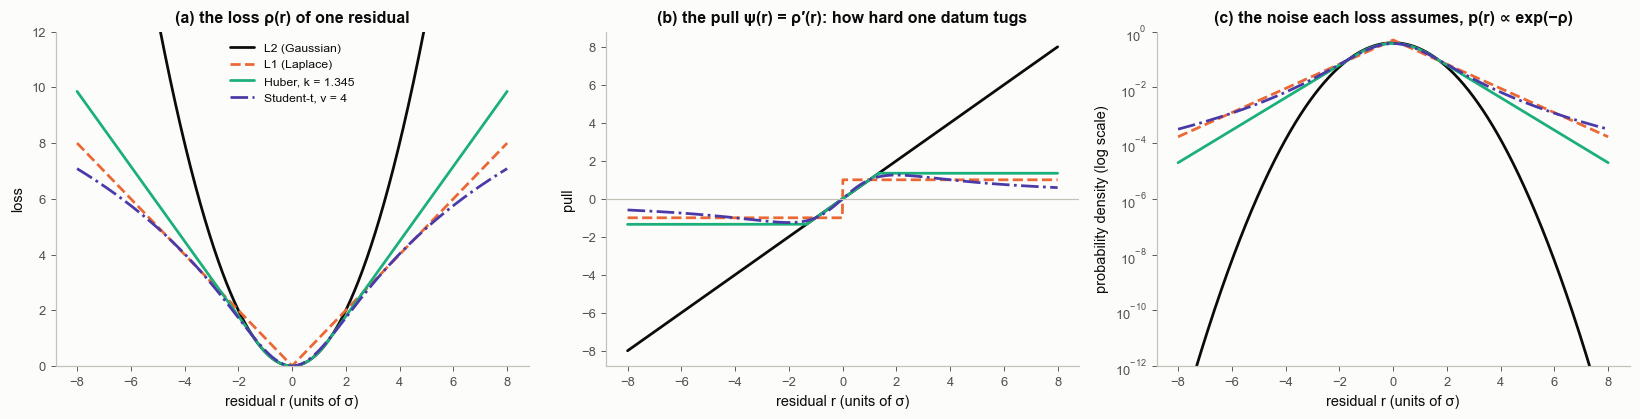

In [2]:
K_HUB, NU_T = 1.345, 4.0
LOSSES = {
    "L2 (Gaussian)": (lambda r: 0.5 * r ** 2, lambda r: r),
    "L1 (Laplace)": (lambda r: np.abs(r), lambda r: np.sign(r)),
    "Huber, k = 1.345": (lambda r: np.where(np.abs(r) <= K_HUB, 0.5 * r ** 2, K_HUB * np.abs(r) - 0.5 * K_HUB ** 2),
                         lambda r: np.clip(r, -K_HUB, K_HUB)),
    "Student-t, ν = 4": (lambda r: 0.5 * (NU_T + 1) * np.log1p(r ** 2 / NU_T), lambda r: (NU_T + 1) * r / (NU_T + r ** 2)),
}
LCOL = dict(zip(LOSSES, [S.INK, S.ORANGE, S.AQUA, S.VIOLET]))
LSTY = dict(zip(LOSSES, ["-", "--", "-", "-."]))
r = np.linspace(-8, 8, 1601)
rw = np.linspace(-200, 200, 400001)                   # wide grid to normalise the implied densities
fig, axs = plt.subplots(1, 3, figsize=(15, 3.9))
for name, (rho, psi) in LOSSES.items():
    Z = np.trapezoid(np.exp(-rho(rw)), rw)
    axs[0].plot(r, rho(r), color=LCOL[name], ls=LSTY[name], lw=1.8, label=name)
    axs[1].plot(r, psi(r), color=LCOL[name], ls=LSTY[name], lw=1.8, label=name)
    axs[2].semilogy(r, np.exp(-rho(r)) / Z, color=LCOL[name], ls=LSTY[name], lw=1.8, label=name)
axs[0].set_ylim(0, 12); axs[0].set_title("(a) the loss ρ(r) of one residual"); axs[0].set_ylabel("loss")
axs[1].set_title("(b) the pull ψ(r) = ρ′(r): how hard one datum tugs"); axs[1].set_ylabel("pull")
axs[1].axhline(0, color=S.AXIS, lw=0.8)
axs[2].set_title("(c) the noise each loss assumes, p(r) ∝ exp(−ρ)"); axs[2].set_ylabel("probability density (log scale)")
axs[2].set_ylim(1e-12, 1)
for ax in axs:
    ax.set_xlabel("residual r (units of σ)")
axs[0].legend(fontsize=8, loc="upper center")
fig.tight_layout()
bk.savefig(fig, "2-10_losses")
plt.show()

**How to read it.** (a) All four losses agree for small residuals (within about one σ); they differ in how fast they
grow. (b) The pull is the important difference: under L2 a datum 8σ off pulls eight times harder than one 1σ off,
under L1 and Huber it pulls no harder than a moderate residual, and under Student-t it pulls *less* (the fit decides
the datum is an outlier and largely ignores it). (c) The same choice seen as a noise model, on a log scale: the
Gaussian tail falls so fast that a 6σ residual is essentially impossible, which is why a single outlier must bend an
L2 fit.

**Worked example.** One residual of 1σ and one of 10σ. For each loss the code prints $\rho$, the pull $\psi$, and the
probability the implied noise model gives to a residual at least that large.

In [3]:
print(f"{'loss':20s} {'rho(1)':>8s} {'rho(10)':>8s} {'psi(1)':>8s} {'psi(10)':>8s} {'P(|r|>=10)':>12s}")
for name, (rho, psi) in LOSSES.items():
    dens = np.exp(-rho(rw)); dens /= np.trapezoid(dens, rw)
    tail = 2 * np.trapezoid(dens[rw >= 10], rw[rw >= 10])          # both tails (the densities are symmetric)
    print(f"{name:20s} {rho(1.0):8.3f} {rho(10.0):8.3f} {psi(1.0):8.3f} {psi(10.0):8.3f} {tail:12.2e}")
print("\n(the Gaussian tail value is analytic: 2 * (1 - Phi(10)) =", f"{2 * st.norm.sf(10):.2e})")

loss                   rho(1)  rho(10)   psi(1)  psi(10)   P(|r|>=10)
L2 (Gaussian)           0.500   50.000    1.000   10.000     1.52e-23
L1 (Laplace)            1.000   10.000    1.000    1.000     4.54e-05
Huber, k = 1.345        0.500   12.545    1.000    1.345     1.99e-06
Student-t, ν = 4        0.558    8.145    1.000    0.481     5.62e-04

(the Gaussian tail value is analytic: 2 * (1 - Phi(10)) = 1.52e-23)


**Common misreadings.**
* *"Least squares is the neutral, assumption-free choice."* It is the maximum-likelihood answer for Gaussian noise
  and nothing else; it trusts the data's error bars completely, including the one datum that is wrong.
* *"A robust loss throws away data."* It down-weights large residuals by a rule stated in advance (the pull). It is
  still a likelihood, so it still has a posterior.

## 2. Outliers in a GPS series: the loss decides the velocity

**In plain words.** A station records 80 positions over four years; eight of them (10 %) are pushed upward by 10 to
30 mm (snow on the antenna, a multipath season). Fit the velocity with each of the four losses and repeat the whole
experiment with 400 fresh noise draws, once with the outliers and once without, to see bias and scatter.

**Precisely.** Each robust fit is solved by iteratively reweighted least squares (IRLS): weights
$w_i = \psi(r_i)/r_i$ from the current residuals, a weighted least-squares solve, repeat. At convergence the
gradient of $\sum\rho(r_i)$ is zero.

In [4]:
t80 = np.linspace(0, 4, 80)
G80 = np.column_stack([np.ones_like(t80), t80])
A_TRUE, B_TRUE, S80 = 0.0, 10.0, 2.0                    # mm, mm/yr, mm


def irls(G, d, sigma, name, n_iter=100):
    """Minimise sum rho((d - G m) / sigma) by iteratively reweighted least squares, starting from least squares."""
    m = np.linalg.lstsq(G, d, rcond=None)[0]
    if name.startswith("L2"):
        return m
    psi = LOSSES[name][1]
    for _ in range(n_iter):
        rr = (d - G @ m) / sigma
        w = np.where(np.abs(rr) > 1e-9, psi(rr) / np.where(np.abs(rr) > 1e-9, rr, 1.0), 1.0)
        w = np.maximum(w, 1e-9)
        sw = np.sqrt(w)
        m_new = np.linalg.lstsq(G * sw[:, None], d * sw, rcond=None)[0]
        if np.max(np.abs(m_new - m)) < 1e-10:
            return m_new
        m = m_new
    return m


def gps_series(rng, outliers=True):
    d = A_TRUE + B_TRUE * t80 + S80 * rng.standard_normal(t80.size)
    bad = np.zeros(t80.size, bool)
    if outliers:
        bad[rng.choice(t80.size, 8, replace=False)] = True
        d[bad] += rng.uniform(10, 30, bad.sum())
    return d, bad


rng = np.random.default_rng(21)
d_ex, bad_ex = gps_series(rng)
fits_ex = {name: irls(G80, d_ex, S80, name) for name in LOSSES}
vel = {(name, out): [] for name in LOSSES for out in (False, True)}
for out in (False, True):
    rr_ = np.random.default_rng(100 + out)
    for rep in range(400):
        dd, _ = gps_series(rr_, out)
        for name in LOSSES:
            vel[(name, out)].append(irls(G80, dd, S80, name)[1])
sd_ls = S80 / np.sqrt(np.sum((t80 - t80.mean()) ** 2))
print("one example series (8 outliers): fitted offset (mm) and velocity (mm/yr); true", A_TRUE, B_TRUE)
for name in LOSSES:
    print(f"   {name:20s} a = {fits_ex[name][0]:7.3f}   b = {fits_ex[name][1]:7.3f}")
print(f"\n400 repeats: velocity error b - b_true (mm/yr). The formal least-squares sd, sigma / sqrt(sum (t - mean t)^2), "
      f"is {sd_ls:.3f} whatever the data contain")
print(f"{'loss':20s} {'clean: mean':>12s} {'clean: sd':>10s} {'10% outl.: mean':>16s} {'10% outl.: sd':>14s}")
for name in LOSSES:
    c, o = np.array(vel[(name, False)]) - B_TRUE, np.array(vel[(name, True)]) - B_TRUE
    print(f"{name:20s} {c.mean():12.3f} {c.std():10.3f} {o.mean():16.3f} {o.std():14.3f}")
off = {name: [] for name in LOSSES}
rr_ = np.random.default_rng(101)
for rep in range(400):
    dd, _ = gps_series(rr_, True)
    for name in LOSSES:
        off[name].append(irls(G80, dd, S80, name)[0])
print("\n400 repeats with 10 % outliers: offset error a - a_true (mm), mean and sd")
for name in LOSSES:
    o = np.array(off[name]) - A_TRUE
    print(f"   {name:20s} mean {o.mean():6.3f}   sd {o.std():6.3f}")

one example series (8 outliers): fitted offset (mm) and velocity (mm/yr); true 0.0 10.0
   L2 (Gaussian)        a =   1.670   b =  10.335
   L1 (Laplace)         a =   0.717   b =   9.770
   Huber, k = 1.345     a =   0.438   b =   9.957
   Student-t, ν = 4     a =   0.286   b =   9.911

400 repeats: velocity error b - b_true (mm/yr). The formal least-squares sd, sigma / sqrt(sum (t - mean t)^2), is 0.191 whatever the data contain
loss                  clean: mean  clean: sd  10% outl.: mean  10% outl.: sd
L2 (Gaussian)              -0.008      0.198           -0.046          0.636
L1 (Laplace)               -0.008      0.249           -0.012          0.265
Huber, k = 1.345           -0.005      0.203           -0.013          0.244
Student-t, ν = 4           -0.006      0.207           -0.008          0.216

400 repeats with 10 % outliers: offset error a - a_true (mm), mean and sd
   L2 (Gaussian)        mean  2.088   sd  1.299
   L1 (Laplace)         mean  0.312   sd  0.596
   Huber,

saved figures/2-10_outliers.png


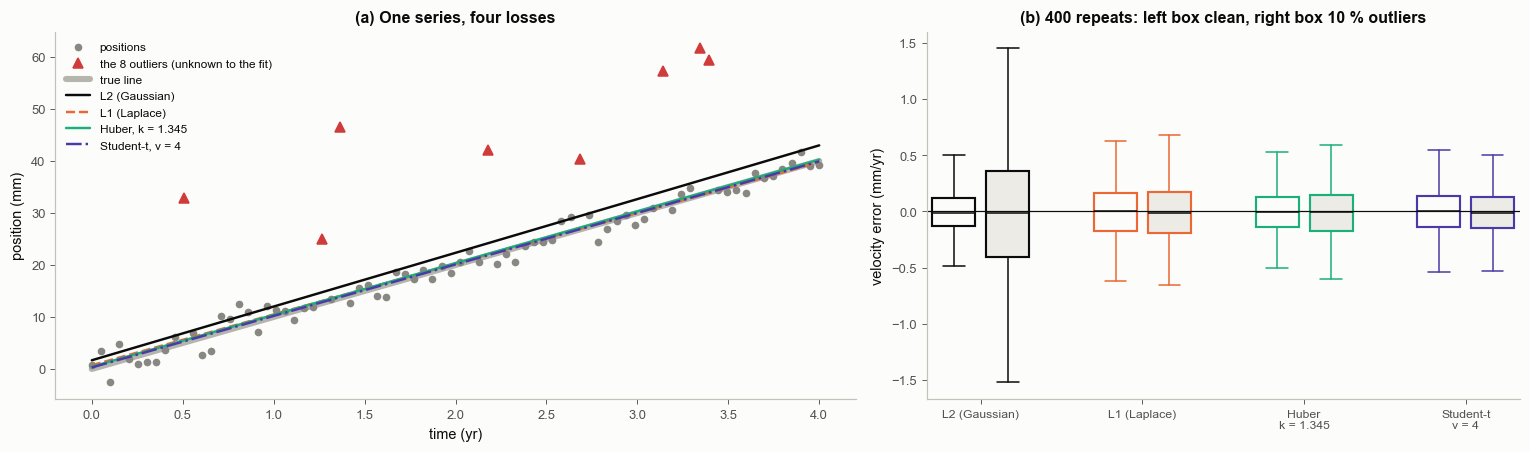

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw=dict(width_ratios=[1.35, 1]))
ax = axs[0]
ax.plot(t80[~bad_ex], d_ex[~bad_ex], "o", color=S.MUTED, ms=4, label="positions")
ax.plot(t80[bad_ex], d_ex[bad_ex], "^", color=S.BAD, ms=6, label="the 8 outliers (unknown to the fit)")
tt = np.linspace(0, 4, 50)
ax.plot(tt, A_TRUE + B_TRUE * tt, color="#b5b4ad", lw=4, zorder=1, label="true line")
for name in LOSSES:
    ax.plot(tt, fits_ex[name][0] + fits_ex[name][1] * tt, color=LCOL[name], ls=LSTY[name], lw=1.6, label=name)
ax.set_xlabel("time (yr)"); ax.set_ylabel("position (mm)")
ax.set_title("(a) One series, four losses")
ax.legend(fontsize=7.8, loc="upper left")
ax = axs[1]
names = list(LOSSES)
for j, name in enumerate(names):
    for k, out in enumerate((False, True)):
        e = np.array(vel[(name, out)]) - B_TRUE
        pos = j * 3 + k
        bp = ax.boxplot(e, positions=[pos], widths=0.8, patch_artist=True, showfliers=False,
                        medianprops=dict(color=S.INK), whiskerprops=dict(color=LCOL[name]), capprops=dict(color=LCOL[name]))
        bp["boxes"][0].set(facecolor=S.SURFACE if not out else "#ecebe6", edgecolor=LCOL[name], lw=1.4)
ax.axhline(0, color=S.INK, lw=0.8)
ax.set_xticks([j * 3 + 0.5 for j in range(4)])
ax.set_xticklabels([n.replace(", ", "\n") for n in names], fontsize=8)
ax.set_ylabel("velocity error (mm/yr)")
ax.set_title("(b) 400 repeats: left box clean, right box 10 % outliers")
fig.tight_layout()
bk.savefig(fig, "2-10_outliers")
plt.show()

**How to read it.** (a) The L2 line is lifted by the eight outliers; the robust lines stay close to the true line.
(b) Each pair of boxes is one loss: white without outliers, grey with them. Read the printed tables with it.
With clean Gaussian data least squares is (as the Gauss-Markov theorem promises, 2.07) the most precise; Huber and
Student-t are almost as precise, and L1 scatters noticeably more. With outliers the L2 velocity box widens several
fold while its centre stays near zero: the outliers fall at random times, so they tilt each fit by a random amount
rather than in one direction. The offset tells the other half of the story (second table): all outliers push upward,
so the L2 offset is biased. The robust losses keep both small.

**The image to keep.** Choosing the loss is choosing the noise model. If the noise model is wrong, the estimate is
biased where the bad data are systematic (the offset) and scattered where they are random (the velocity), and the
formal L2 error bar (printed) knows about neither: it is the same number with and without outliers.

## 3. Losses for surrogates: judge errors in units of the data noise

Topic 3 trains surrogates (fast stand-ins for the forward model, 3.01-3.05). A surrogate is also fitted by minimising a
loss, now over training runs instead of data, and the same question arises: what should the loss measure?

**In plain words.** A surrogate's errors will end up next to GPS residuals inside a likelihood (3.03, 3.07). What
matters there is the error in units of the data noise. A loss on *relative* error (error divided by the size of the
signal) sounds fair, but it spends effort on runs with tiny displacements, below what GPS can see, and neglects the
large ones.

**Precisely.** Three common surrogate losses over training runs $j$ and outputs $k$ (here 40 epochs):

$$\text{MSE} = \frac1{JK}\sum_{j,k}(\hat u_{jk}-u_{jk})^2,\qquad
\text{relative} = \frac1{JK}\sum_{j,k}\Big(\frac{\hat u_{jk}-u_{jk}}{\max_k\lvert u_{jk}\rvert}\Big)^2,\qquad
\text{noise-weighted} = \frac1{JK}\sum_{j,k}\Big(\frac{\hat u_{jk}-u_{jk}}{\sigma_k}\Big)^2 .$$

With one σ for every output (as here) the noise-weighted loss is MSE divided by σ². When outputs have different noise
(east vs up, GPS vs InSAR) only the noise-weighted form puts the effort where the likelihood will look. A fourth loss
also learns the surrogate's own error size $s_k$: the Gaussian negative log-likelihood
$\text{NLL} = \sum_{j,k}\big[\tfrac{(\hat u_{jk}-u_{jk})^2}{2s_k^2} + \ln s_k\big] + \text{const}$, whose $\ln s_k$
term stops it from claiming errors larger than they are, and whose first term stops it from claiming smaller ones.

**Worked example.** Fit a degree-5 polynomial in the three scaled parameters (56 coefficients per epoch) to 3,000
cached runs of the single-patch afterslip model (explained at the start of section 4;
`bayeskit.afterslip.training_set_single`), once by MSE and once by relative error, and test both on 1,000 other runs
(*test* runs are held back from the fit to grade it; *validation* runs, below, are held back to tune it). Errors are reported in units of σ = 2 mm.

In [6]:
th_tr, u_tr = A.training_set_single(4000, seed=0)
lo3, hi3 = A.SP_BOUNDS[:, 0], A.SP_BOUNDS[:, 1]
z3 = 2 * (th_tr - lo3) / (hi3 - lo3) - 1


def poly_features(z, deg):
    cols = [np.ones(len(z))]
    for kk in range(1, deg + 1):
        for c in combinations_with_replacement(range(z.shape[1]), kk):
            cols.append(np.prod(z[:, list(c)], axis=1))
    return np.column_stack(cols)


F5 = poly_features(z3, 5)
Y = u_tr / SIG                                          # outputs in units of the GPS noise
tr, va, te = slice(0, 3000), slice(3000, 3500), slice(3500, 4000)
scale = np.abs(Y).max(axis=1)
W_mse = np.linalg.lstsq(F5[tr], Y[tr], rcond=None)[0]
W_rel = np.linalg.lstsq(F5[tr] / scale[tr, None], Y[tr] / scale[tr, None], rcond=None)[0]
print(f"{F5.shape[1]} coefficients per epoch, {Y.shape[1]} epochs; signal size max|u| over the test runs: "
      f"{np.percentile(scale[te] * SIG * 1e3, 5):.1f} mm (5th percentile) to {np.percentile(scale[te] * SIG * 1e3, 95):.0f} mm (95th)")
big = scale[te] > np.median(scale[te])
print(f"{'fit':10s} {'RMS error, all (sigma)':>24s} {'small-signal half':>18s} {'large-signal half':>18s}")
for name, W in [("MSE", W_mse), ("relative", W_rel)]:
    E = F5[te] @ W - Y[te]
    print(f"{name:10s} {np.sqrt((E ** 2).mean()):24.2f} {np.sqrt((E[~big] ** 2).mean()):18.2f} {np.sqrt((E[big] ** 2).mean()):18.2f}")

# NLL with a learned error size per epoch: s_k from the validation runs, NLL evaluated on the test runs
E_va, E_te = F5[va] @ W_mse - Y[va], F5[te] @ W_mse - Y[te]
s_k = np.sqrt((E_va ** 2).mean(axis=0))
cs = np.geomspace(0.1, 10, 201)
nll = np.array([np.mean(0.5 * E_te ** 2 / (c * s_k) ** 2 + np.log(c * s_k) + 0.5 * np.log(2 * np.pi)) for c in cs])
c_best = cs[np.argmin(nll)]
print(f"\nNLL on the test runs is lowest when the claimed error size is c = {c_best:.2f} times the validation estimate")
print(f"NLL penalty for claiming errors 3x too small: {np.interp(1/3, cs, nll) - nll.min():.2f} per value; "
      f"3x too large: {np.interp(3, cs, nll) - nll.min():.2f} per value")

56 coefficients per epoch, 40 epochs; signal size max|u| over the test runs: 7.5 mm (5th percentile) to 879 mm (95th)
fit          RMS error, all (sigma)  small-signal half  large-signal half
MSE                            6.05               5.52               6.53
relative                      17.88               4.56              24.88

NLL on the test runs is lowest when the claimed error size is c = 1.02 times the validation estimate
NLL penalty for claiming errors 3x too small: 3.18 per value; 3x too large: 0.62 per value


saved figures/2-10_surrogate_losses.png


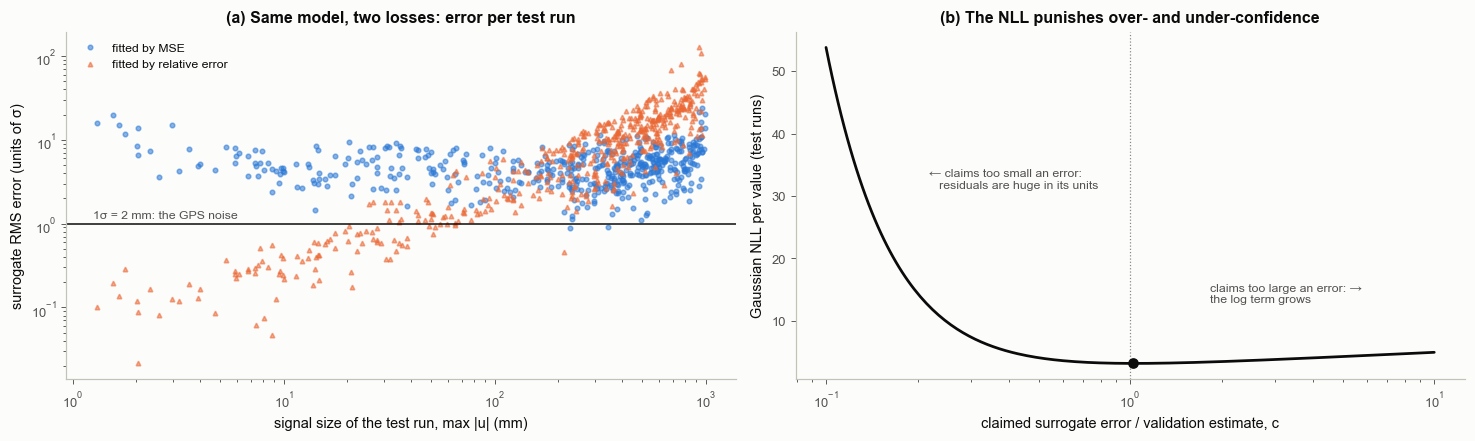

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(13.5, 4.1))
ax = axs[0]
for name, W, col, mk in [("fitted by MSE", W_mse, S.BLUE, "o"), ("fitted by relative error", W_rel, S.ORANGE, "^")]:
    E = F5[te] @ W - Y[te]
    ax.loglog(scale[te] * SIG * 1e3, np.sqrt((E ** 2).mean(axis=1)), mk, color=col, ms=3, alpha=0.55, label=name)
ax.axhline(1, color=S.INK, lw=1)
ax.text(1.25, 1.15, "1σ = 2 mm: the GPS noise", fontsize=8, color=S.INK2)
ax.set_xlabel("signal size of the test run, max |u| (mm)"); ax.set_ylabel("surrogate RMS error (units of σ)")
ax.set_title("(a) Same model, two losses: error per test run")
ax.legend(fontsize=8, loc="upper left")
ax = axs[1]
ax.semilogx(cs, nll, color=S.INK, lw=1.8)
ax.axvline(1, color=S.MUTED, lw=0.8, ls=":")
ax.plot(c_best, nll.min(), "o", color=S.INK)
ax.set_xlabel("claimed surrogate error / validation estimate, c")
ax.set_ylabel("Gaussian NLL per value (test runs)")
ax.set_title("(b) The NLL punishes over- and under-confidence")
ax.text(0.2, 0.55, "← claims too small an error:\n   residuals are huge in its units", transform=ax.transAxes, fontsize=8, color=S.INK2)
ax.text(0.62, 0.22, "claims too large an error: →\nthe log term grows", transform=ax.transAxes, fontsize=8, color=S.INK2)
fig.tight_layout()
bk.savefig(fig, "2-10_surrogate_losses")
plt.show()

**How to read it.** (a) Each dot is one test run. The MSE fit (blue) makes errors of about the same absolute size
everywhere, several σ, which for the smallest runs is larger than the whole signal. The relative-error fit (orange)
is far more accurate on small runs and many σ off on the large ones (the printed table splits the test runs at the
median signal size). Neither is uniformly better: the loss decides *where* a surrogate is accurate. For inference the
accuracy that counts is in units of σ and in the part of parameter space the posterior occupies, which is why 3.01 and
3.03 measure errors there and 3.03 trains where the posterior is. (b) If the surrogate also reports how wrong it is,
the NLL is the loss that keeps that report honest: its minimum sits near the validation estimate (the printed $c$),
and both directions of dishonesty cost, under-confidence less than over-confidence (printed).

**Common misreadings.**
* *"A 1 % relative error is small."* On a 500 mm afterslip signal it is 5 mm, which is 2.5σ of GPS noise. Always
  convert surrogate errors to units of the data noise.
* *"This polynomial is a usable surrogate."* Its errors are several σ (printed above); 3.01 builds better ones. Here it
  only shows what the loss rewards.

## 4. Six optimisers on a real nonlinear landscape

**The forward model: stress-driven afterslip on one fault patch.** An earthquake raises the shear stress on a fault
patch next to the rupture by $\Delta\tau$ (MPa). The patch responds by slipping slowly for months (*afterslip*). Its
slip speed follows a friction law, $v = 2v_0\sinh(\tau/a\sigma)$: no stress, no motion, and the speed grows
exponentially with stress. $a\sigma$ (MPa) sets how sensitive the speed is to stress, and $v_0$ (m/yr) is a reference
speed. Slipping relieves the stress, $\dot\tau = -k v$, where the stiffness $k$ is the stress lost per metre of slip.
So the patch slips fast at first and then more and more slowly, and a GPS station above it records a displacement
$u(t) = g\,s(t)$ (slip $s$ times a geometric factor $g$) that grows roughly with the logarithm of time.

This is an *ordinary differential equation* (ODE) in time, solved step by step. It is *stiff*: it changes very fast at
first and slowly later, so it needs an adaptive implicit solver. We use diffrax, a library built on JAX, a Python
system that can also differentiate the whole computation with respect to the parameters (2.17, 2.22).

Synthetic data: $a\sigma$ = 0.5 MPa, $v_0$ = 0.03 m/yr, $\Delta\tau$ = 3 MPa (known in this section), 40 epochs,
σ = 2 mm. The solver runs inside every loss evaluation.
The loss is the misfit $\mathcal L = \tfrac12\chi^2 = \tfrac12\sum_i r_i^2$ (a flat prior inside the prior box of
`SP_BOUNDS`; every optimiser is kept inside that box).

The forward function below is `bayeskit.afterslip.single_patch_series` with the parameters passed to the solver as
arguments, so that 2.22's derivative options can be switched; the first printed line checks that the two agree.

**The six optimisers** (one line each; they differ in what they know about the landscape):

| optimiser | update | needs | knows about curvature? |
|---|---|---|---|
| gradient descent (GD) + backtracking line search | $\mathbf x \leftarrow \mathbf x - \eta\nabla\mathcal L$, halve $\eta$ until the loss drops enough | gradient | no |
| momentum (heavy ball) | $\mathbf u \leftarrow \beta\mathbf u - \eta\nabla\mathcal L$, $\mathbf x \leftarrow \mathbf x + \mathbf u$ | gradient | no (remembers the past direction) |
| Adam (Kingma & Ba 2015) | momentum, with each coordinate's step divided by its running RMS gradient | gradient | per coordinate only |
| Gauss-Newton (GN) | $\mathbf x \leftarrow \mathbf x - (\mathbf J^\top\mathbf J)^{-1}\mathbf J^\top\mathbf r$ | Jacobian $\mathbf J = \partial\mathbf r/\partial\mathbf x$ | yes: $\mathbf J^\top\mathbf J$ approximates the Hessian |
| Levenberg-Marquardt (LM) | $(\mathbf J^\top\mathbf J + \mu\,\mathrm{diag}\,\mathbf J^\top\mathbf J)\,\boldsymbol\delta = \mathbf J^\top\mathbf r$, raise $\mu$ when a step fails | Jacobian | yes, with a safety brake |
| L-BFGS (scipy) | quasi-Newton: builds curvature from the last few gradients | gradient | learned on the way |

Words in the table: the **gradient** $\nabla\mathcal L$ is the slope of the loss in every parameter direction; a
*line search* tries a step and shrinks it until the loss really drops; *RMS* is root-mean-square; the **Jacobian**
$\mathbf J$ is the table of slopes of every residual with respect to every parameter (drawn after the worked example
below); the **Hessian** is the curvature of the loss (2.08); *quasi-Newton* methods build an approximation to the
Hessian from the gradients seen so far.

scipy has no Adam; the ten lines below are the whole algorithm (Kingma & Ba 2015).

In [8]:
DTAU = 3.0
X_TRUE = np.array([np.log(0.5), np.log(0.03)])
LO2, HI2 = A.SP_BOUNDS[:2, 0], A.SP_BOUNDS[:2, 1]


def _rhs(t, y, args):
    a_s, v0, k = args
    v = 2.0 * v0 * jnp.sinh(y[0] / a_s)
    return jnp.stack([-k * v, v])


def afterslip_u(theta3, t_obs=A.T_OBS, adjoint=dfx.RecursiveCheckpointAdjoint(), rtol=1e-7, k=3.0, g=0.6):
    """Same model as afterslip.single_patch_series; theta3 = (log a_sigma, log v0, dtau); parameters passed as args."""
    sol = dfx.diffeqsolve(dfx.ODETerm(_rhs), dfx.Kvaerno5(), t0=0.0, t1=float(t_obs[-1]), dt0=1e-7,
                          y0=jnp.stack([theta3[2], 0.0 * theta3[2]]), args=(jnp.exp(theta3[0]), jnp.exp(theta3[1]), k),
                          saveat=dfx.SaveAt(ts=jnp.asarray(t_obs)), max_steps=200_000, adjoint=adjoint,
                          stepsize_controller=dfx.PIDController(rtol=rtol, atol=rtol * 1e-2))
    return g * sol.ys[:, 1]


u2 = lambda x, **kw: afterslip_u(jnp.stack([x[0], x[1], DTAU]), **kw)
print("max |local forward - bayeskit.afterslip.single_patch_series| =",
      f"{float(jnp.max(jnp.abs(u2(jnp.asarray(X_TRUE)) - A.single_patch_series(jnp.array([*X_TRUE, DTAU]), A.T_OBS, rtol=1e-7, atol=1e-9)))):.1e} m")
d_as = np.asarray(u2(jnp.asarray(X_TRUE))) + SIG * np.random.default_rng(11).standard_normal(A.T_OBS.size)
resid = jax.jit(lambda x: (u2(x) - d_as) / SIG)
loss = jax.jit(lambda x: 0.5 * jnp.sum(resid(x) ** 2))
loss_grad = jax.jit(jax.value_and_grad(lambda x: 0.5 * jnp.sum(((u2(x) - d_as) / SIG) ** 2)))
jac_fwd = jax.jit(jax.jacfwd(lambda x: (u2(x, adjoint=dfx.ForwardMode()) - d_as) / SIG))   # 2 tangent solves
L_true = float(loss(jnp.asarray(X_TRUE)))
print(f"loss at the true parameters: {L_true:.2f}  (chi^2 = {2 * L_true:.1f} for N = {A.T_OBS.size} data)")

# the landscape, on a 45 x 45 grid over the prior box (2,025 ODE solves, vectorised)
ga, gv = np.linspace(LO2[0], HI2[0], 45), np.linspace(LO2[1], HI2[1], 45)
GA, GV = np.meshgrid(ga, gv)
loss_batch = jax.jit(jax.vmap(lambda x: 0.5 * jnp.sum(((u2(x, rtol=1e-6) - d_as) / SIG) ** 2)))
t_ = time.time()
LG = np.asarray(loss_batch(jnp.asarray(np.c_[GA.ravel(), GV.ravel()]))).reshape(GA.shape)
print(f"landscape: {GA.size} solves in {time.time() - t_:.1f} s; loss from {LG.min():.0f} to {LG.max():.2e}")

max |local forward - bayeskit.afterslip.single_patch_series| = 1.2e-14 m


loss at the true parameters: 14.46  (chi^2 = 28.9 for N = 40 data)


landscape: 2025 solves in 2.5 s; loss from 36 to 7.75e+05


In [9]:
def adam(x, grad_fn, lr=0.05, n=500, b1=0.9, b2=0.999, eps=1e-8):
    m, v, path = np.zeros_like(x), np.zeros_like(x), [x.copy()]
    for t in range(1, n + 1):
        g = grad_fn(x)
        m = b1 * m + (1 - b1) * g                       # running mean of the gradient (momentum)
        v = b2 * v + (1 - b2) * g * g                   # running mean of its square
        step = lr * (m / (1 - b1 ** t)) / (np.sqrt(v / (1 - b2 ** t)) + eps)   # bias-corrected, per-coordinate scale
        x = np.clip(x - step, LO2, HI2)
        path.append(x.copy())
    return np.array(path)


import inspect
print(inspect.getsource(adam))

def adam(x, grad_fn, lr=0.05, n=500, b1=0.9, b2=0.999, eps=1e-8):
    m, v, path = np.zeros_like(x), np.zeros_like(x), [x.copy()]
    for t in range(1, n + 1):
        g = grad_fn(x)
        m = b1 * m + (1 - b1) * g                       # running mean of the gradient (momentum)
        v = b2 * v + (1 - b2) * g * g                   # running mean of its square
        step = lr * (m / (1 - b1 ** t)) / (np.sqrt(v / (1 - b2 ** t)) + eps)   # bias-corrected, per-coordinate scale
        x = np.clip(x - step, LO2, HI2)
        path.append(x.copy())
    return np.array(path)



**Worked example: one gradient step and one Gauss-Newton step.** From the start $\mathbf x_0$ = (log 1.5, log 0.003)
the code prints the loss, the gradient, the step that the line search accepts, and the Gauss-Newton step
$-(\mathbf J^\top\mathbf J)^{-1}\mathbf J^\top\mathbf r$ with the two matrices it is built from.

In [10]:
X0 = np.array([np.log(1.5), np.log(0.003)])
L0, g0 = (np.asarray(v) for v in loss_grad(jnp.asarray(X0)))
print(f"start x0 = {X0}, loss {float(L0):.1f}")
print(f"gradient at x0: {g0}   (length {np.linalg.norm(g0):.3e})")
eta = 1.0
while float(loss(jnp.asarray(np.clip(X0 - eta * g0, LO2, HI2)))) > float(L0) - 1e-4 * eta * g0 @ g0:
    eta /= 2
print(f"GD: largest step size eta = 2^-k accepted by the line search: {eta:.3e};  step = {-eta * g0};  "
      f"new loss {float(loss(jnp.asarray(np.clip(X0 - eta * g0, LO2, HI2)))):.1f}")
J0, r0 = np.asarray(jac_fwd(jnp.asarray(X0))), np.asarray(resid(jnp.asarray(X0)))
print("GN: J^T J =\n", J0.T @ J0, "\n    J^T r =", J0.T @ r0)
step_gn = -np.linalg.solve(J0.T @ J0, J0.T @ r0)
print(f"    step = {step_gn};  new loss {float(loss(jnp.asarray(np.clip(X0 + step_gn, LO2, HI2)))):.1f}  (after clipping to the prior box)")
print(f"    eigenvalues of J^T J at x0: {np.linalg.eigvalsh(J0.T @ J0)}")

start x0 = [ 0.4055 -5.8091], loss 238166.1
gradient at x0: [15652.3079 -7586.5598]   (length 1.739e+04)
GD: largest step size eta = 2^-k accepted by the line search: 1.221e-04;  step = [-1.9107  0.9261];  new loss 189207.9


GN: J^T J =
 [[ 650.9097 -315.7987]
 [-315.7987  153.2154]] 
    J^T r = [15652.3079 -7586.5598]
    step = [-4417.5223 -9055.6271];  new loss 107111.8  (after clipping to the prior box)
    eigenvalues of J^T J at x0: [  0.0007 804.1244]


The gradient step is cautious (the line search shrank it until the loss dropped). The Gauss-Newton step is thousands
of units long: far from the minimum $\mathbf J^\top\mathbf J$ is nearly singular (one eigenvalue is tiny, printed),
so the linearised model behind Gauss-Newton predicts a minimum far away. Only the clipping to the prior box keeps the
step inside; Levenberg-Marquardt's damping $\mu$ exists for exactly this.

**The Jacobian, drawn.** In plain words: for each datum, how much does its prediction change when one parameter is
nudged? Precisely, $J_{ij} = \partial r_i/\partial x_j$, one row per datum (here 40 epochs) and one column per parameter
(here 2). It is the local straight-line version of the forward model, $\mathbf g(\mathbf x + \boldsymbol\delta) \approx
\mathbf g(\mathbf x) + \sigma\mathbf J\boldsymbol\delta$, which is what Gauss-Newton, the extended Kalman filter (2.25) and the
Laplace approximation (section 9) all rely on. Left: the prediction at one epoch as $\log v_0$ is nudged, and the
tangent line whose slope is one entry of $\mathbf J$. Right: the two columns of $\mathbf J$ at the true parameters,
converted to millimetres of displacement per unit change of each log-parameter.

epoch 22 is day 27.9: predicted displacement 187.88 mm; slope d u / d log v0 there (Jacobian entry) 84.71 mm per unit log v0
tangent vs exact at the largest nudge (+-0.6): differences +2.66 mm and +2.02 mm
cosine between the two Jacobian columns: -0.977  (-1: exactly opposite directions, 0: unrelated)


saved figures/2-10_jacobian.png


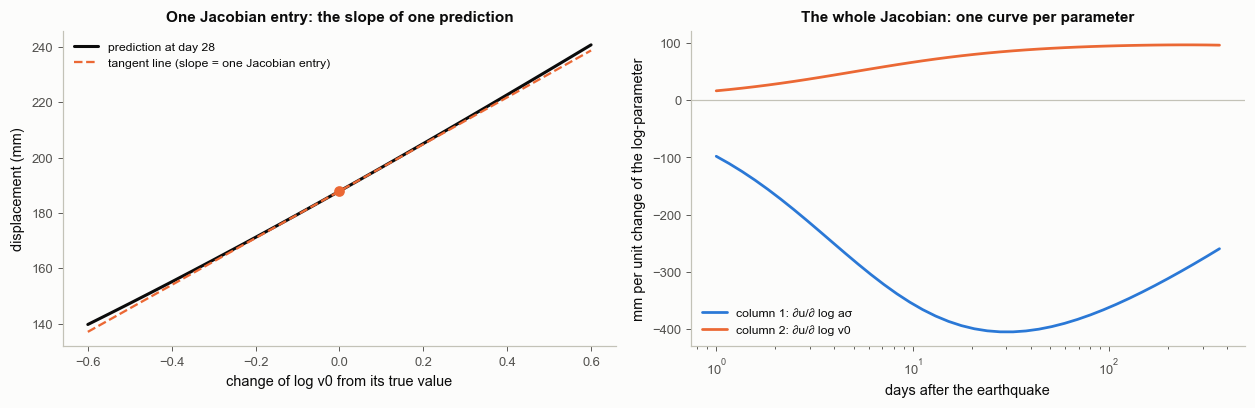

In [11]:
J_t = np.asarray(jac_fwd(jnp.asarray(X_TRUE))) * SIG * 1000.0       # mm per unit log-parameter
k_ep = int(np.argmin(np.abs(365.25 * A.T_OBS - 30.0)))               # the epoch closest to day 30
dv = np.linspace(-0.6, 0.6, 25)
u_k = np.array([1000.0 * float(u2(jnp.asarray(X_TRUE + np.array([0.0, e])))[k_ep]) for e in dv])
u_0 = 1000.0 * float(u2(jnp.asarray(X_TRUE))[k_ep])
print(f"epoch {k_ep} is day {365.25 * A.T_OBS[k_ep]:.1f}: predicted displacement {u_0:.2f} mm; "
      f"slope d u / d log v0 there (Jacobian entry) {J_t[k_ep, 1]:.2f} mm per unit log v0")
print(f"tangent vs exact at the largest nudge (+-0.6): differences {u_k[0] - (u_0 - 0.6 * J_t[k_ep, 1]):+.2f} mm and "
      f"{u_k[-1] - (u_0 + 0.6 * J_t[k_ep, 1]):+.2f} mm")
cos_J = J_t[:, 0] @ J_t[:, 1] / (np.linalg.norm(J_t[:, 0]) * np.linalg.norm(J_t[:, 1]))
print(f"cosine between the two Jacobian columns: {cos_J:.3f}  (-1: exactly opposite directions, 0: unrelated)")
fig, axs = plt.subplots(1, 2, figsize=(11.5, 3.8))
ax = axs[0]
ax.plot(dv, u_k, color=S.INK, lw=2, label=f"prediction at day {365.25 * A.T_OBS[k_ep]:.0f}")
ax.plot(dv, u_0 + J_t[k_ep, 1] * dv, color=S.ORANGE, lw=1.5, ls="--", label="tangent line (slope = one Jacobian entry)")
ax.plot(0, u_0, "o", color=S.ORANGE, ms=6)
ax.set_xlabel("change of log v0 from its true value"); ax.set_ylabel("displacement (mm)")
ax.set_title("One Jacobian entry: the slope of one prediction", fontsize=10)
ax.legend(fontsize=8, loc="upper left")
ax = axs[1]
days = 365.25 * A.T_OBS
ax.semilogx(days, J_t[:, 0], color=S.BLUE, lw=1.8, label="column 1: ∂u/∂ log aσ")
ax.semilogx(days, J_t[:, 1], color=S.ORANGE, lw=1.8, label="column 2: ∂u/∂ log v0")
ax.axhline(0, color=S.AXIS, lw=0.8)
ax.set_xlabel("days after the earthquake"); ax.set_ylabel("mm per unit change of the log-parameter")
ax.set_title("The whole Jacobian: one curve per parameter", fontsize=10)
ax.legend(fontsize=8)
fig.tight_layout()
bk.savefig(fig, "2-10_jacobian")
plt.show()

**How to read it.** Left: near the true value the prediction and its tangent agree, and they part slowly as the nudge
grows (differences printed): over this range the prediction is only mildly curved in $\log v_0$, but a Jacobian is
always a local description. Right: raising $a\sigma$ lowers every prediction and raising $v_0$ raises it, by amounts
that change with time; the shapes differ ($a\sigma$ matters most around the first month, $v_0$ most late). Because
the two columns have opposite signs at every epoch, they point in nearly opposite directions (cosine printed), so
raising both parameters together changes the predictions much less than raising either alone. That partial
cancellation is the trade-off between $a\sigma$ and $v_0$ that makes the valley of the next figure long and narrow.

In [12]:
def run_gd(x, n=300):
    path, runs, eta = [x.copy()], [0], 1.0
    nr = 0
    for _ in range(n):
        v, g = (np.asarray(q) for q in loss_grad(jnp.asarray(x))); nr += 2          # forward + reverse sweep
        eta *= 2
        while True:
            xn = np.clip(x - eta * g, LO2, HI2); vn = float(loss(jnp.asarray(xn))); nr += 1
            if vn <= float(v) - 1e-4 * eta * g @ g or eta < 1e-30:
                break
            eta /= 2
        x = xn; path.append(x.copy()); runs.append(nr)
    return np.array(path), np.array(runs)


def run_momentum(x, eta, beta=0.9, n=500):
    u, path = np.zeros_like(x), [x.copy()]
    for _ in range(n):
        g = np.asarray(loss_grad(jnp.asarray(x))[1])
        u = beta * u - eta * g
        x = np.clip(x + u, LO2, HI2); path.append(x.copy())
    return np.array(path), 2 * np.arange(n + 1)


def run_gn(x, lm=False, n=60):
    path, runs, nr, mu = [x.copy()], [0], 1, 1e-3
    Lx = float(loss(jnp.asarray(x)))
    for _ in range(n):
        J, rr = np.asarray(jac_fwd(jnp.asarray(x))), np.asarray(resid(jnp.asarray(x))); nr += 3   # forward + 2 tangents
        H = J.T @ J
        while True:
            step = np.linalg.solve(H + (mu * np.diag(np.diag(H)) if lm else 0), J.T @ rr)
            xn = np.clip(x - step, LO2, HI2); Ln = float(loss(jnp.asarray(xn))); nr += 1
            if not lm or Ln < Lx or mu > 1e12:
                break
            mu *= 10
        if lm:
            mu = max(mu / 10, 1e-9)
        x, Lx = xn, Ln; path.append(x.copy()); runs.append(nr)
        if np.abs(step).max() < 1e-10:
            break
    return np.array(path), np.array(runs)


def run_lbfgs(x):
    path, runs, nr = [x.copy()], [0], [0]

    def fun(z):
        nr[0] += 2
        v, g = loss_grad(jnp.asarray(z))
        return float(v), np.asarray(g)

    def cb(z):
        path.append(z.copy()); runs.append(nr[0])

    res = minimize(fun, x, jac=True, method="L-BFGS-B", bounds=list(zip(LO2, HI2)), callback=cb,
                   options=dict(maxiter=500, gtol=1e-10, ftol=1e-15))
    return np.array(path), np.array(runs), res


grad_np = lambda x: np.asarray(loss_grad(jnp.asarray(x))[1])
OPT = {}
t_ = time.time(); p, rn = run_gd(X0.copy()); OPT["gradient descent"] = (p, rn, time.time() - t_)
t_ = time.time(); p, rn, res_lb = run_lbfgs(X0.copy()); OPT["L-BFGS"] = (p, rn, time.time() - t_)
x_best = res_lb.x
J_best = np.asarray(jac_fwd(jnp.asarray(x_best)))
lam_max = np.linalg.eigvalsh(J_best.T @ J_best).max()
t_ = time.time(); p, rn = run_momentum(X0.copy(), eta=1.0 / lam_max); OPT["momentum"] = (p, rn, time.time() - t_)
t_ = time.time(); p = adam(X0.copy(), grad_np); OPT["Adam"] = (p, 2 * np.arange(len(p)), time.time() - t_)
t_ = time.time(); p, rn = run_gn(X0.copy()); OPT["Gauss-Newton"] = (p, rn, time.time() - t_)
t_ = time.time(); p, rn = run_gn(X0.copy(), lm=True); OPT["Levenberg-Marquardt"] = (p, rn, time.time() - t_)
OCOL = {"gradient descent": S.MUTED, "momentum": S.ORANGE, "Adam": S.AQUA, "Gauss-Newton": S.VIOLET,
        "Levenberg-Marquardt": S.VIOLET, "L-BFGS": S.BLUE}
OSTY = {"gradient descent": "-", "momentum": "-", "Adam": "-", "Gauss-Newton": "-", "Levenberg-Marquardt": "--", "L-BFGS": "-"}
L_best = min(float(loss(jnp.asarray(p[-1]))) for p, _, _ in OPT.values())
print(f"momentum step size eta = 1 / (largest eigenvalue of J^T J at the minimum) = {1 / lam_max:.2e}  (uses knowledge of the answer)")
print(f"lowest loss found: {L_best:.4f};  'converged' below means loss <= lowest + 0.5 (chi^2 within 1)\n")
print(f"{'optimiser':20s} {'iterations':>10s} {'solver runs':>12s} {'seconds':>8s} {'final loss':>12s} {'iter. to converge':>18s} {'runs to converge':>17s}")
for name, (p, rn, sec) in OPT.items():
    Ls = np.array([float(loss(jnp.asarray(q))) for q in p])
    ok = np.where(Ls <= L_best + 0.5)[0]
    it_c = f"{ok[0]}" if ok.size else "not reached"
    rn_c = f"{rn[ok[0]]}" if ok.size else "-"
    OPT[name] = (p, rn, sec, Ls)
    print(f"{name:20s} {len(p) - 1:10d} {rn[-1]:12d} {sec:8.1f} {Ls[-1]:12.3f} {it_c:>18s} {rn_c:>17s}")
print(f"\nbest-fit parameters: a_sigma = {np.exp(x_best[0]):.4f} MPa, v0 = {np.exp(x_best[1]):.4f} m/yr  (true 0.5, 0.03)")

momentum step size eta = 1 / (largest eigenvalue of J^T J at the minimum) = 9.37e-07  (uses knowledge of the answer)
lowest loss found: 13.9706;  'converged' below means loss <= lowest + 0.5 (chi^2 within 1)

optimiser            iterations  solver runs  seconds   final loss  iter. to converge  runs to converge


gradient descent            300         1219      8.1      333.194        not reached                 -
L-BFGS                       10           32      0.6       13.971                  5                22


momentum                    500         1000      6.2       13.971                167               334


Adam                        500         1000      7.0       15.669        not reached                 -
Gauss-Newton                  9           37      0.1       13.971                  4                17
Levenberg-Marquardt           9           47      0.1       13.971                  5                21

best-fit parameters: a_sigma = 0.5005 MPa, v0 = 0.0300 m/yr  (true 0.5, 0.03)


saved figures/2-10_optimiser_paths.png


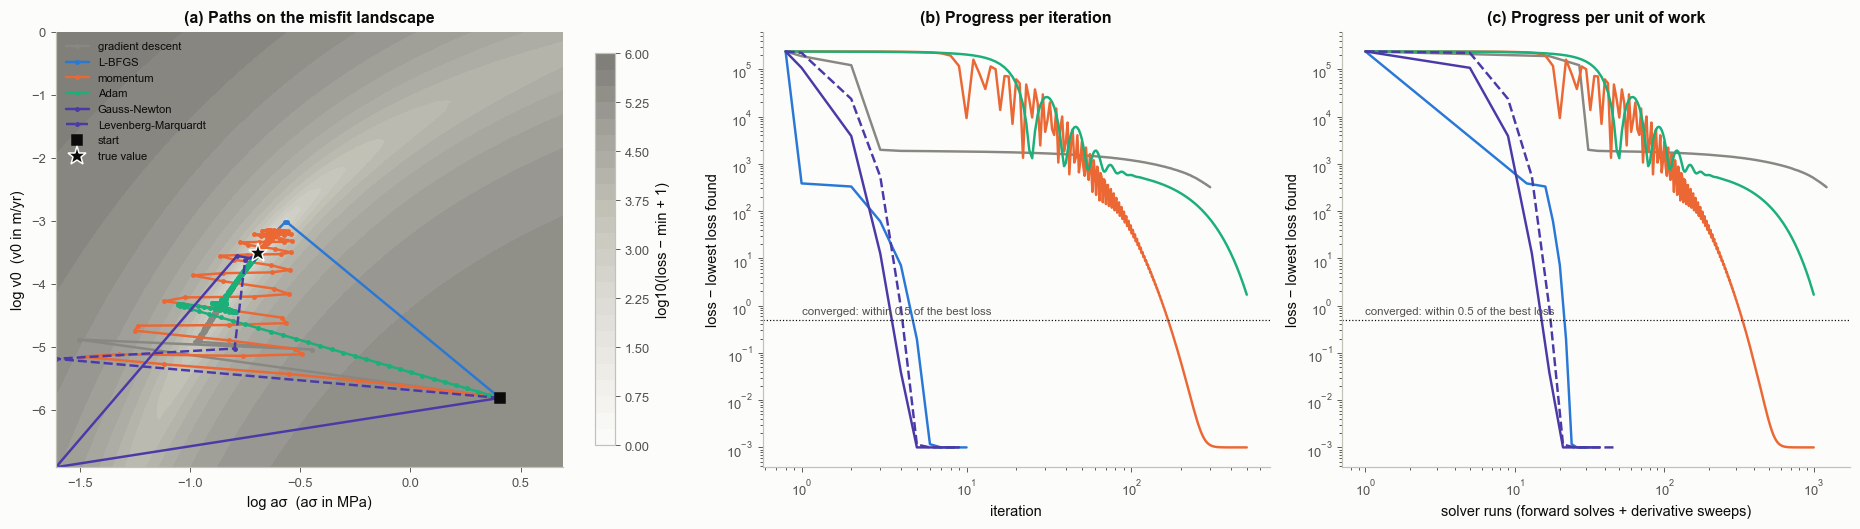

In [13]:
LGplot = np.log10(LG - LG.min() + 1.0)
fig, axs = plt.subplots(1, 3, figsize=(17, 4.9), gridspec_kw=dict(width_ratios=[1.25, 1, 1]))
ax = axs[0]
cf = ax.contourf(GA, GV, LGplot, levels=24, cmap=S.GREYS)
fig.colorbar(cf, ax=ax, label="log10(loss − min + 1)", shrink=0.9)
for name, (p, rn, sec, Ls) in OPT.items():
    ax.plot(p[:, 0], p[:, 1], color=OCOL[name], ls=OSTY[name], lw=1.6, marker="o", ms=2.2, label=name)
ax.plot(*X0, "s", color=S.INK, ms=7, label="start")
ax.plot(*X_TRUE, "*", color=S.INK, ms=13, mec=S.SURFACE, label="true value")
ax.set_xlabel("log aσ  (aσ in MPa)"); ax.set_ylabel("log v0  (v0 in m/yr)")
ax.set_title("(a) Paths on the misfit landscape")
ax.legend(fontsize=7.4, loc="upper left")
for ax, xkey, xlab in [(axs[1], "iter", "iteration"), (axs[2], "runs", "solver runs (forward solves + derivative sweeps)")]:
    for name, (p, rn, sec, Ls) in OPT.items():
        xx = np.arange(len(Ls)) if xkey == "iter" else np.maximum(rn, 1)
        ax.loglog(np.maximum(xx, 0.8), Ls - L_best + 1e-3, color=OCOL[name], ls=OSTY[name], lw=1.6, label=name)
    ax.axhline(0.5, color=S.INK, lw=0.8, ls=":")
    ax.text(1.0, 0.65, "converged: within 0.5 of the best loss", fontsize=7.5, color=S.INK2)
    ax.set_xlabel(xlab); ax.set_ylabel("loss − lowest loss found")
axs[1].set_title("(b) Progress per iteration"); axs[2].set_title("(c) Progress per unit of work")
fig.tight_layout()
bk.savefig(fig, "2-10_optimiser_paths")
plt.show()

**How to read it.** (a) The misfit valley is long, narrow and curved: the data pin down a combination of $a\sigma$
and $v_0$ much better than either alone, because both control how fast the afterslip curve rises. The curvature
methods (Gauss-Newton, Levenberg-Marquardt, L-BFGS) jump into the valley and run along it in a few steps.
Gradient descent falls into the valley, then creeps; with a step small enough not to bounce off the steep walls, it
barely moves along the floor and has not arrived after 300 iterations. Momentum builds up speed along the floor and
arrives after a few hundred iterations, with a step size chosen from the answer (printed). Adam, with a standard
learning rate, is close but still outside the tolerance after 500. (b, c) The table above gives the exact counts;
panel (c) charges every method for its solver runs, which is what costs time when the forward model is expensive.

**The image to keep.** On a narrow valley, a method that only knows the slope (the gradient) is slow, and one that
also knows the curvature (Gauss-Newton family, quasi-Newton) is fast. Adam is the standard choice for training
neural networks (3.02), where curvature is too expensive to compute, not because it is the fastest optimiser for a
small physical problem.

59 frames, 1.17 MB



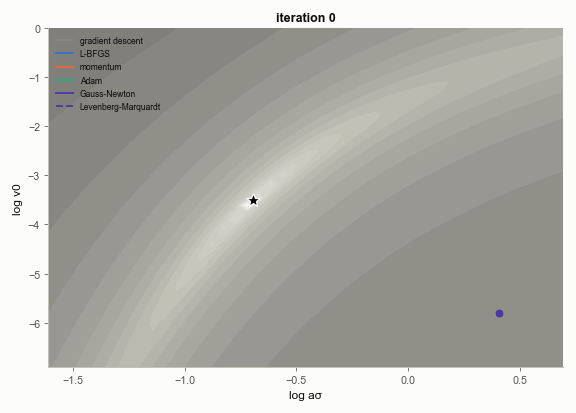

the last frame at full resolution:
saved figures/2-10_optimiser_race_final.png


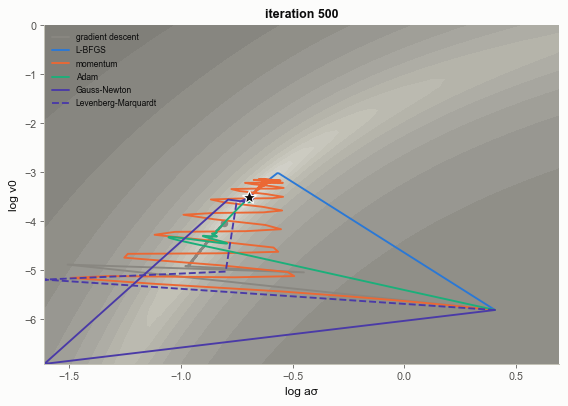

In [14]:
sched = sorted(set(np.r_[np.arange(0, 12), np.unique(np.geomspace(12, 500, 48).astype(int))]))
def race_frame(it):
    fig, ax = plt.subplots(figsize=(6.4, 4.6), dpi=90)
    ax.contourf(GA, GV, LGplot, levels=24, cmap=S.GREYS)
    for name, (p, rn, sec, Ls) in OPT.items():
        q = p[: min(it, len(p) - 1) + 1]
        ax.plot(q[:, 0], q[:, 1], color=OCOL[name], ls=OSTY[name], lw=1.5, label=name)
        ax.plot(*q[-1], "o", color=OCOL[name], ms=5)
    ax.plot(*X_TRUE, "*", color=S.INK, ms=12, mec=S.SURFACE)
    ax.set_xlabel("log aσ"); ax.set_ylabel("log v0")
    ax.set_title(f"iteration {it}", fontsize=10)
    ax.legend(fontsize=6.8, loc="upper left")
    fig.tight_layout()
    return fig


frames = []
for it in sched:
    fig = race_frame(it)
    frames.append(S.fig_to_rgb(fig)); plt.close(fig)
gif = S.frames_to_gif(frames, S.FIG / "2-10_optimiser_race.gif", fps=8)
print(f"{len(frames)} frames, {gif.stat().st_size / 1e6:.2f} MB")
S.show_gif(gif)
print("the last frame at full resolution:")
fig = race_frame(sched[-1])
bk.savefig(fig, "2-10_optimiser_race_final")
plt.show()

The animation runs the same six paths in time (the iteration counter is roughly logarithmic, so early frames are
one iteration apart and late ones dozens). Watch the curvature methods finish while gradient descent is still on the
valley floor.

## 5. Scaling and preconditioning: the same problem can be easy or hard

**In plain words.** How hard a valley is for a gradient method depends on how stretched it is: a round bowl takes a
step or two, a long thin trough takes thousands. Stretch has two sources. Parameters whose effects differ greatly in
size stretch the bowl along the axes; rescaling each parameter (dividing by a typical value, or by its own curvature)
cures that. Parameters that trade off tilt the bowl; only a change of variables that mixes them cures that. Neither
changes the answer, only the work needed to find it.

**Precisely.** Near the minimum $\mathcal L \approx \mathcal L^\ast + \tfrac12\boldsymbol\delta^\top\mathbf H\boldsymbol\delta$.
The condition number $\kappa = \lambda_{\max}(\mathbf H)/\lambda_{\min}(\mathbf H)$ measures the stretch: gradient
descent with the safe step $1/\lambda_{\max}$ needs about $\tfrac{\kappa}{2}\ln(1/\epsilon)$ iterations to reduce the
loss excess by a factor $\epsilon$. A change of variables $\boldsymbol\delta = \mathbf P\mathbf z$ turns $\mathbf H$ into
$\mathbf P^\top\mathbf H\mathbf P$. A diagonal $\mathbf P = \mathrm{diag}(H_{ii})^{-1/2}$ removes the axis stretch
(for two parameters with Hessian correlation $\rho$ it leaves $\kappa = (1+|\rho|)/(1-|\rho|)$); the full
$\mathbf P = \mathbf H^{-1/2}$ (whitening, 2.06) gives $\kappa = 1$. Newton-type methods do the full version
implicitly; a diagonal or dense *mass matrix*, the sampler's own rescaling of the parameters, does the same for
HMC/NUTS (notebook 2.18).

**Worked example.** The Gauss-Newton Hessian $\mathbf J^\top\mathbf J$ at the minimum, in four sets of units: raw
($a\sigma$ in MPa, $v_0$ in m/yr), log, log with each parameter rescaled by its own curvature (diagonal), and
whitened. Then gradient descent with the step $1/\lambda_{\max}$ on each quadratic, from
the same physical starting point (the start of section 4), until the loss excess drops below $10^{-6}$ of its start.

In [15]:
H_log = J_best.T @ J_best
Dchain = np.diag(np.exp(x_best))                        # d(raw)/d(log) = raw value
H_raw = np.linalg.inv(Dchain) @ H_log @ np.linalg.inv(Dchain)
P_diag = np.diag(np.diag(H_log) ** -0.5)
H_diag = P_diag @ H_log @ P_diag
ev_l, U_l = np.linalg.eigh(H_log)
P_white = U_l @ np.diag(ev_l ** -0.5) @ U_l.T
H_white = P_white.T @ H_log @ P_white
rho_H = H_log[0, 1] / np.sqrt(H_log[0, 0] * H_log[1, 1])
COND = {}
for name, H in [("raw units (MPa, m/yr)", H_raw), ("log units", H_log), ("log, rescaled per parameter", H_diag),
                ("whitened", H_white)]:
    ev = np.linalg.eigvalsh(H)
    COND[name] = (H, ev[-1] / ev[0])
    print(f"{name:28s} eigenvalues {ev}   condition number {ev[-1] / ev[0]:.3e}")
print(f"Hessian correlation rho = {rho_H:.4f};  (1 + |rho|) / (1 - |rho|) = {(1 + abs(rho_H)) / (1 - abs(rho_H)):.1f}")


def gd_quadratic(H, z0, tol=1e-6, nmax=200_000):
    ev = np.linalg.eigvalsh(H)
    eta = 1 / ev[-1]
    z, path, f0 = z0.copy(), [z0.copy()], 0.5 * z0 @ H @ z0
    for k in range(nmax):
        z = z - eta * H @ z
        if k < 40:
            path.append(z.copy())
        if 0.5 * z @ H @ z < tol * f0:
            return np.array(path), k + 1
    return np.array(path), None


dz_log = X0 - x_best
starts = {"raw units (MPa, m/yr)": np.exp(X0) - np.exp(x_best), "log units": dz_log,
          "log, rescaled per parameter": np.linalg.solve(P_diag, dz_log), "whitened": np.linalg.solve(P_white, dz_log)}
GDQ = {}
for name, (H, kap) in COND.items():
    path, nit = gd_quadratic(H, starts[name])
    GDQ[name] = (path, nit)
    print(f"{name:28s} gradient descent with step 1/lambda_max needs {nit if nit else '> 200,000'} iterations "
          f"(kappa/2 ln(1e6) = {kap / 2 * np.log(1e6):.3g})")

raw units (MPa, m/yr)        eigenvalues [  169789.8918 65301315.6135]   condition number 3.846e+02
log units                    eigenvalues [   2345.6326 1066747.9211]   condition number 4.548e+02
log, rescaled per parameter  eigenvalues [0.0226 1.9774]   condition number 8.765e+01
whitened                     eigenvalues [1. 1.]   condition number 1.000e+00
Hessian correlation rho = -0.9774;  (1 + |rho|) / (1 - |rho|) = 87.7
raw units (MPa, m/yr)        gradient descent with step 1/lambda_max needs 1993 iterations (kappa/2 ln(1e6) = 2.66e+03)
log units                    gradient descent with step 1/lambda_max needs 1854 iterations (kappa/2 ln(1e6) = 3.14e+03)
log, rescaled per parameter  gradient descent with step 1/lambda_max needs 314 iterations (kappa/2 ln(1e6) = 605)
whitened                     gradient descent with step 1/lambda_max needs 1 iterations (kappa/2 ln(1e6) = 6.91)


saved figures/2-10_conditioning.png


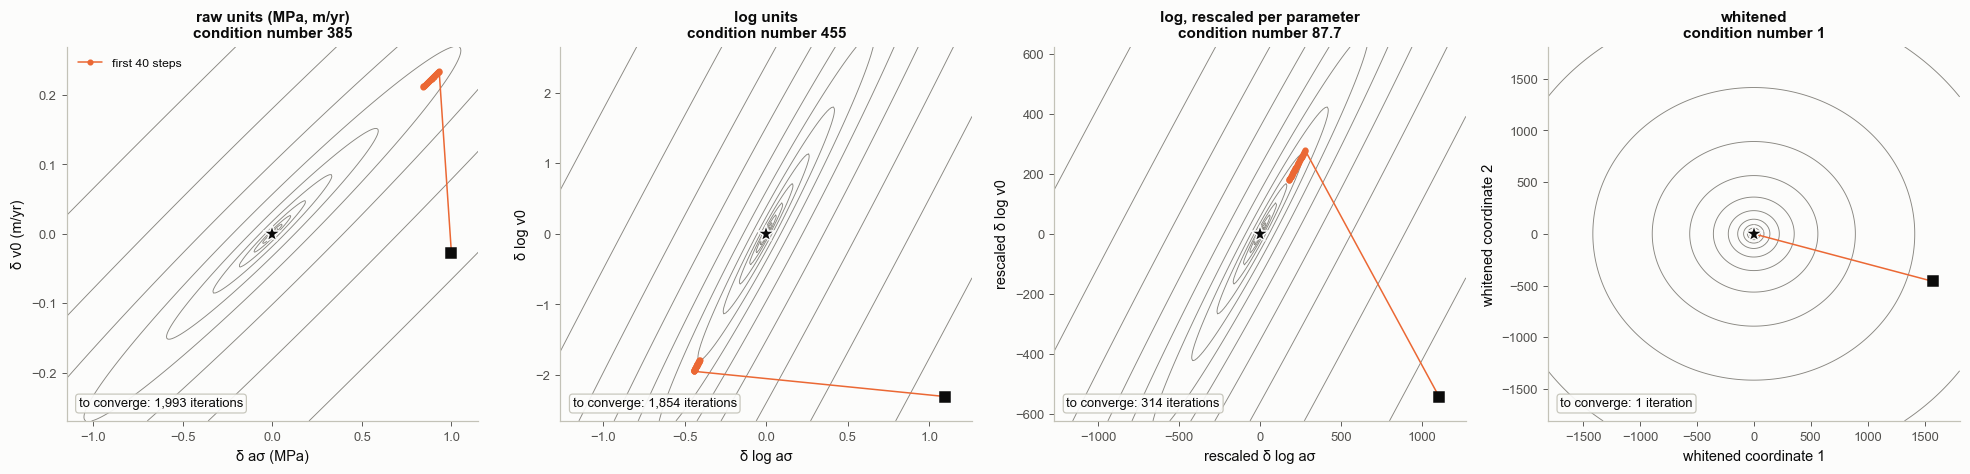

In [16]:
fig, axs = plt.subplots(1, 4, figsize=(18, 4.4))
LABS = {"raw units (MPa, m/yr)": ("δ aσ (MPa)", "δ v0 (m/yr)"), "log units": ("δ log aσ", "δ log v0"),
        "log, rescaled per parameter": ("rescaled δ log aσ", "rescaled δ log v0"),
        "whitened": ("whitened coordinate 1", "whitened coordinate 2")}
for ax, (name, (H, kap)) in zip(axs, COND.items()):
    path, nit = GDQ[name]
    span = 1.15 * np.abs(path).max(axis=0)
    if name == "whitened":
        span = np.full(2, 1.15 * np.abs(path).max())
    xs_, ys_ = np.linspace(-span[0], span[0], 200), np.linspace(-span[1], span[1], 200)
    Xq, Yq = np.meshgrid(xs_, ys_)
    Q = 0.5 * (H[0, 0] * Xq ** 2 + 2 * H[0, 1] * Xq * Yq + H[1, 1] * Yq ** 2)
    ax.contour(Xq, Yq, np.log10(Q + 1e-12), levels=14, colors=S.MUTED, linewidths=0.6)
    ax.plot(path[:, 0], path[:, 1], "o-", color=S.ORANGE, ms=3, lw=1, label="first 40 steps")
    ax.plot(path[0, 0], path[0, 1], "s", color=S.INK, ms=6)
    ax.plot(0, 0, "*", color=S.INK, ms=12, mec=S.SURFACE)
    ax.set_title(f"{name}\ncondition number {kap:.3g}", fontsize=10)
    ax.set_xlabel(LABS[name][0]); ax.set_ylabel(LABS[name][1])
    S.badge(ax, (f"to converge: {nit:,} iteration" + ("s" if nit != 1 else "")) if nit else "to converge: > 200,000 iterations", ok=None, loc="lower left")
axs[0].legend(fontsize=8, loc="upper left")
fig.tight_layout()
bk.savefig(fig, "2-10_conditioning")
plt.show()

**How to read it.** Each panel is the same quadratic bowl (the local picture of the afterslip valley at its minimum)
drawn in different units, with the first 40 steps of gradient descent from the same physical starting point (square)
to the minimum (star). In raw and in log units the bowl is a long tilted trough: the first step drops to its floor,
and the following steps crawl along the floor (the dots bunch up). At this minimum the two are about equally
stretched (printed condition numbers). Rescaling each
parameter by its own curvature helps, but the trough stays tilted: its remaining stretch is set by the correlation
(the printed $\rho$ formula). Whitened, the bowl is round and one step lands at the bottom. The printed iteration
counts are of the size the $\kappa/2\,\ln(1/\epsilon)$ rule predicts (the rule is an upper estimate: it assumes
all of the starting error lies along the floor).

**Common misreadings.**
* *"Parameter units are cosmetic."* For the answer, yes; for any gradient-based method (optimiser or NUTS), no.
  Log-transforming a positive parameter is mainly about positivity and about ranges that span orders of magnitude; at
  this particular minimum it barely changes the stretch (printed), a reminder to measure rather than assume.
* *"A diagonal rescaling is enough."* Only if the valley is aligned with the axes. This one is tilted (strong
  correlation), which only a full (dense) preconditioner or a curvature method removes.

## 6. Several starts, several answers: when the minimum is not a point

**In plain words.** Now let $\Delta\tau$ be unknown too and start L-BFGS from 16 random points of the prior box.
For $\Delta\tau \gg a\sigma$ the model depends on $v_0$ and $\Delta\tau$ only through
$v_+ = v_0\,e^{\Delta\tau/a\sigma}$ (the module docstring's log formula), so there is a whole line of equally good
fits. Different starts end at different points on it.

**Precisely.** A direction in parameter space along which the loss does not change is non-identifiable. Gradient-based
optimisers stop wherever they first reach the flat floor, so the end point depends on the start. Separately, a stiff
solver can fail at extreme parameter values; here a failed solve returns NaN ("not a number", what a failed
computation returns; the environment variable set in the first cell arranges this), the wrapper reports a huge loss,
and the line search may give up. The convergence message says which happened.

In [17]:
d3 = d_as                                               # the same data as section 4
loss_grad3 = jax.jit(jax.value_and_grad(lambda th: 0.5 * jnp.sum(((afterslip_u(th) - d3) / SIG) ** 2)))
TH_TRUE = np.array([np.log(0.5), np.log(0.03), DTAU])


N_BAD = [0]                                             # non-finite evaluations in the current run


def fun3(th):
    v, g = loss_grad3(jnp.asarray(th))
    v, g = float(v), np.asarray(g)
    if not np.isfinite(v) or not np.all(np.isfinite(g)):
        N_BAD[0] += 1
        return 1e20, np.zeros(3)                       # failed solve: tell the line search this point is terrible
    return v, g


starts3 = A.sample_theta(np.random.default_rng(3), 16)
MS = []
t_ = time.time()
NBAD = []
for s0 in starts3:
    N_BAD[0] = 0
    res = minimize(fun3, s0, jac=True, method="L-BFGS-B", bounds=list(map(tuple, A.SP_BOUNDS)),
                   options=dict(maxiter=300, gtol=1e-8))
    MS.append(res); NBAD.append(N_BAD[0])
print(f"16 L-BFGS runs in {time.time() - t_:.1f} s")
L_ms = np.array([r_.fun for r_ in MS])
good = L_ms < L_ms.min() + 0.5
comb = lambda th: th[1] + th[2] / np.exp(th[0])         # log v_plus = log v0 + dtau / a_sigma
print(f"{'start':>5s} {'a_sigma':>8s} {'v0':>8s} {'dtau':>6s} {'final loss':>11s} {'|gradient|':>11s} {'log v+':>7s} {'iters':>5s} {'NaN evals':>9s}  scipy's message")
for i, r_ in enumerate(MS):
    x = r_.x
    gnorm = np.linalg.norm(np.asarray(loss_grad3(jnp.asarray(x))[1]))
    print(f"{i:5d} {np.exp(x[0]):8.3f} {np.exp(x[1]):8.4f} {x[2]:6.3f} {r_.fun:11.2f} {gnorm:11.2e} {comb(x):7.3f} {r_.nit:5d} {NBAD[i]:9d}  {r_.message}")
print("starts stuck above the lowest loss that met a non-finite gradient: "
      f"{sum(1 for i, r_ in enumerate(MS) if r_.fun > min(m.fun for m in MS) + 0.5 and NBAD[i] > 0)} of "
      f"{sum(1 for r_ in MS if r_.fun > min(m.fun for m in MS) + 0.5)}")
print(f"\n{good.sum()} of 16 starts reach the lowest loss (within 0.5); true a_sigma 0.5, v0 0.03, dtau 3, log v+ = {comb(TH_TRUE):.3f}")
xg = np.array([r_.x for r_ in MS])[good]
print(f"among them: v0 from {np.exp(xg[:, 1]).min():.4f} to {np.exp(xg[:, 1]).max():.4f} m/yr, dtau from "
      f"{xg[:, 2].min():.3f} to {xg[:, 2].max():.3f} MPa, log v+ from {comb(xg.T).min():.4f} to {comb(xg.T).max():.4f}")
U_good = np.array([np.asarray(afterslip_u(jnp.asarray(x))) for x in xg])
print(f"largest difference between the predicted series of any two of them: {1e3 * np.ptp(U_good, axis=0).max():.3f} mm  (sigma = 2 mm)")
H3 = np.asarray(jax.hessian(lambda th: 0.5 * jnp.sum(((afterslip_u(th, adjoint=dfx.DirectAdjoint()) - d3) / SIG) ** 2))(jnp.asarray(xg[0])))
ev3 = np.linalg.eigvalsh(H3)
print(f"Hessian eigenvalues at one of them: {ev3}  -> condition number {ev3[-1] / ev3[0]:.2e}")

16 L-BFGS runs in 9.2 s
start  a_sigma       v0   dtau  final loss  |gradient|  log v+ iters NaN evals  scipy's message
    0    0.499   0.0100  3.541       13.89    1.49e-03   2.490    10         0  CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
    1    0.500   0.0124  3.436       13.89    1.19e-02   2.490    11         2  CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
    2    0.603   0.0030  3.938    53192.02    3.68e+05   0.730     1         1  CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
    3    0.500   0.0135  3.393       13.89    1.33e-02   2.490    13         0  CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
    4    0.499   0.0081  3.649       13.89    3.89e-03   2.490    39         0  CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
    5    0.840   0.0398  4.084     5388.48    2.79e+04   1.637     2         2  CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
    6    0.499   0.0081  3.649       13.89    2.30e-04   2.490    28         1  CO

   13    0.839   0.2786  2.577     3420.80    1.02e+04   1.794     4         1  CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
   14    0.499   0.0081  3.649       13.89    3.35e-02   2.490    36         0  CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
   15    0.499   0.0081  3.649       13.89    5.29e-02   2.490    36         1  CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
starts stuck above the lowest loss that met a non-finite gradient: 4 of 4

12 of 16 starts reach the lowest loss (within 0.5); true a_sigma 0.5, v0 0.03, dtau 3, log v+ = 2.493
among them: v0 from 0.0046 to 0.0135 m/yr, dtau from 3.393 to 3.934 MPa, log v+ from 2.4895 to 2.4900
largest difference between the predicted series of any two of them: 0.097 mm  (sigma = 2 mm)


Hessian eigenvalues at one of them: [      0.0101    7000.8664 1853793.6296]  -> condition number 1.84e+08


saved figures/2-10_multistart.png


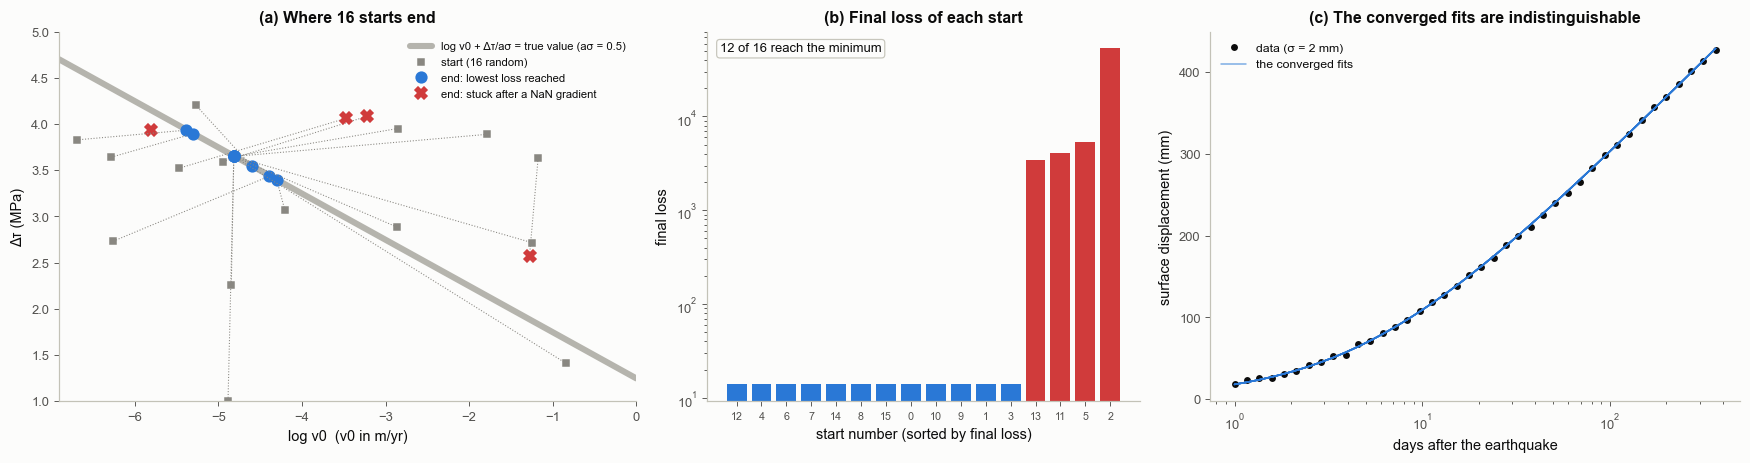

In [18]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.3), gridspec_kw=dict(width_ratios=[1.2, 0.9, 1.1]))
ax = axs[0]
a_hat = np.exp(np.median(xg[:, 0]))
lv = np.linspace(LO2[1], HI2[1], 100)
ax.plot(lv, (comb(TH_TRUE) - lv) * 0.5, color="#b5b4ad", lw=4, zorder=1, label="log v0 + Δτ/aσ = true value (aσ = 0.5)")
for i, r_ in enumerate(MS):
    ok = good[i]
    ax.plot([starts3[i, 1], r_.x[1]], [starts3[i, 2], r_.x[2]], color=S.MUTED, lw=0.7, ls=":")
    ax.plot(starts3[i, 1], starts3[i, 2], "s", color=S.MUTED, ms=4)
    ax.plot(r_.x[1], r_.x[2], "o" if ok else "X", color=S.BLUE if ok else S.BAD, ms=7 if ok else 8)
ax.plot([], [], "s", color=S.MUTED, ms=4, label="start (16 random)")
ax.plot([], [], "o", color=S.BLUE, ms=7, label="end: lowest loss reached")
ax.plot([], [], "X", color=S.BAD, ms=8, label="end: stuck after a NaN gradient")
ax.set_xlim(LO2[1], HI2[1]); ax.set_ylim(*A.SP_BOUNDS[2])
ax.set_xlabel("log v0  (v0 in m/yr)"); ax.set_ylabel("Δτ (MPa)")
ax.set_title("(a) Where 16 starts end")
ax.legend(fontsize=7.4, loc="upper right")
ax = axs[1]
order = np.argsort(L_ms)
ax.bar(range(16), L_ms[order], color=[S.BLUE if good[i] else S.BAD for i in order])
ax.set_yscale("log"); ax.set_xticks(range(16)); ax.set_xticklabels(order, fontsize=7)
ax.set_xlabel("start number (sorted by final loss)"); ax.set_ylabel("final loss")
ax.set_title("(b) Final loss of each start")
S.badge(ax, f"{good.sum()} of 16 reach the minimum", ok=None, loc="upper left")
ax = axs[2]
ax.plot(A.T_OBS * 365.25, d3 * 1e3, "o", color=S.INK, ms=3.5, label="data (σ = 2 mm)")
for k, uu in enumerate(U_good):
    ax.plot(A.T_OBS * 365.25, uu * 1e3, color=S.BLUE, lw=1, alpha=0.6, label="the converged fits" if k == 0 else None)
ax.set_xscale("log")
ax.set_xlabel("days after the earthquake"); ax.set_ylabel("surface displacement (mm)")
ax.set_title("(c) The converged fits are indistinguishable")
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
bk.savefig(fig, "2-10_multistart")
plt.show()

**How to read it.** (a) The blue end points scatter along the grey line: different $(v_0, \Delta\tau)$ pairs with the
same $v_+$, all fitting equally well (b), with predicted series that differ by far less than the noise (c, and the
printed maximum difference). The red crosses are not local minima: their gradient is still large (the printed
|gradient| column). Each of them met a NaN gradient (the "NaN evals" column): a trial step of the line search went
to the edge of the box at the smallest $a\sigma$, where the forward solve still works but its gradient is NaN; after
that L-BFGS-B never moved again, and scipy still printed "CONVERGENCE". The message describes the stopping test, not the answer: always check the
gradient (and the loss) at the end point yourself.

**The image to keep.** "The optimiser converged" can mean "it reached a flat floor somewhere". The spread of end
points along the floor is not an uncertainty estimate (it depends on where the starts were), and a single run hides
it entirely. The printed Hessian condition number is the numerical signature: one direction has almost no curvature.
The posterior answers the question properly: it spreads along the floor according to the prior.

## 7. Mini-batches and stochastic gradients

**In plain words.** When the loss is a sum over very many terms (millions of training examples, 3.02), computing the
full gradient for every step is wasteful. Instead estimate it from a small random subset (a mini-batch) and take many
cheap, noisy steps. One pass through all the data is an epoch.

**Precisely.** For $\mathcal L = \sum_{i=1}^N \ell_i$, the mini-batch gradient $\frac{N}{B}\sum_{i\in\mathcal B}\nabla\ell_i$
is an unbiased but noisy estimate of $\nabla\mathcal L$. With a constant step, stochastic gradient descent does not
converge to the minimum but jitters in a region around it whose size grows with the step and shrinks with the
batch size $B$.

**Worked example.** A long GPS series (2,048 daily positions, σ = 2 mm), straight-line fit, time standardised so the
problem is well conditioned. Batch sizes 1, 16, 256 and 2,048 (full), the same step size, the same 20 epochs, 10
repeats with different shuffles.

In [19]:
N7 = 2048
t7 = np.arange(N7) / 365.25
ts7 = (t7 - t7.mean()) / t7.std()
d7 = 1.0 + 10.0 * t7 + 2.0 * np.random.default_rng(7).standard_normal(N7)
G7 = np.column_stack([np.ones(N7), ts7])
m_exact = np.linalg.lstsq(G7, d7, rcond=None)[0]
mse_exact = np.mean((d7 - G7 @ m_exact) ** 2) / 4.0     # in units of sigma^2


def sgd(B, lr=0.05, epochs=20, seed=0):
    rg = np.random.default_rng(seed)
    m = np.zeros(2)
    hist, tail = [], []
    for ep in range(epochs):
        idx = rg.permutation(N7)
        for s in range(0, N7, B):
            b = idx[s:s + B]
            g = -G7[b].T @ (d7[b] - G7[b] @ m) / len(b) / 4.0      # gradient of the mean squared residual / sigma^2 / 2
            m = m - lr * g
            if ep == epochs - 1:
                tail.append(m.copy())                            # every iterate of the last epoch
        hist.append(np.mean((d7 - G7 @ m) ** 2) / 4.0)
    return m, np.array(hist), np.array(tail)


SGD = {}
for B in [1, 16, 256, N7]:
    runs_ = [sgd(B, seed=s) for s in range(10)]
    SGD[B] = runs_
    fin = np.array([r_[0] for r_ in runs_])
    print(f"batch {B:5d}: {N7 // B:5d} steps per epoch; after 20 epochs, MSE excess over least squares "
          f"{np.mean([r_[1][-1] for r_ in runs_]) - mse_exact:.2e} sigma^2; scatter of the slope over 10 shuffles "
          f"{fin[:, 1].std():.2e} (standardised units)")
sd_slope = np.sqrt(np.linalg.inv(G7.T @ G7)[1, 1] * 4.0)
print(f"for scale: the statistical uncertainty of the least-squares slope is {sd_slope:.2e} (same units)")

batch     1:  2048 steps per epoch; after 20 epochs, MSE excess over least squares 1.15e-02 sigma^2; scatter of the slope over 10 shuffles 1.69e-01 (standardised units)
batch    16:   128 steps per epoch; after 20 epochs, MSE excess over least squares 1.63e-04 sigma^2; scatter of the slope over 10 shuffles 1.38e-02 (standardised units)
batch   256:     8 steps per epoch; after 20 epochs, MSE excess over least squares 4.92e+00 sigma^2; scatter of the slope over 10 shuffles 1.82e-04 (standardised units)
batch  2048:     1 steps per epoch; after 20 epochs, MSE excess over least squares 1.67e+02 sigma^2; scatter of the slope over 10 shuffles 8.43e-16 (standardised units)
for scale: the statistical uncertainty of the least-squares slope is 4.42e-02 (same units)


saved figures/2-10_minibatch.png


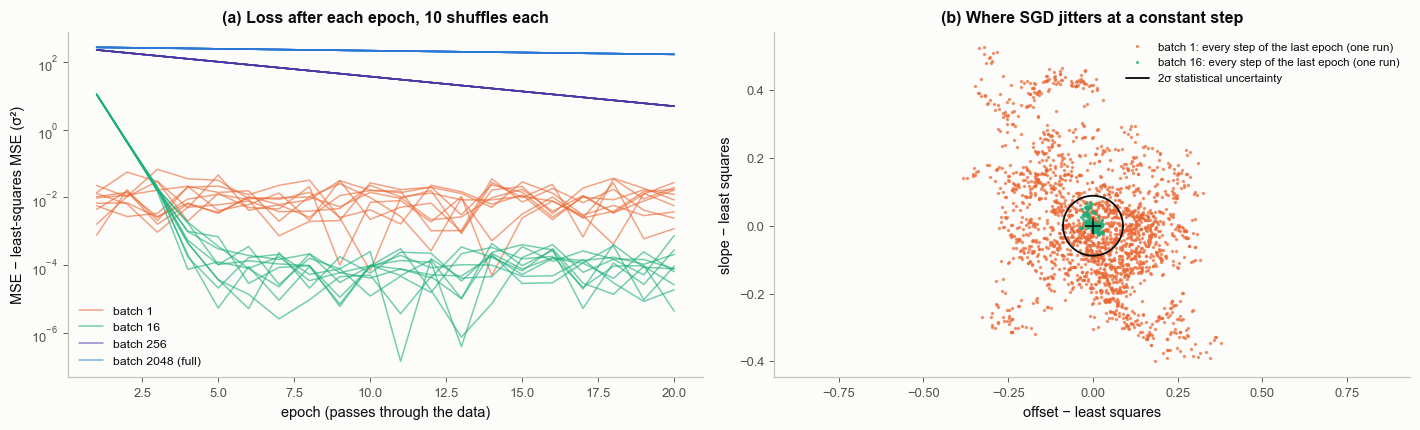

In [20]:
BCOL = {1: S.ORANGE, 16: S.AQUA, 256: S.VIOLET, N7: S.BLUE}
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
ax = axs[0]
for B, runs_ in SGD.items():
    for k, r_ in enumerate(runs_):
        ax.semilogy(np.arange(1, 21), r_[1] - mse_exact + 1e-12, color=BCOL[B], lw=1, alpha=0.6,
                    label=f"batch {B}" + (" (full)" if B == N7 else "") if k == 0 else None)
ax.set_xlabel("epoch (passes through the data)"); ax.set_ylabel("MSE − least-squares MSE (σ²)")
ax.set_title("(a) Loss after each epoch, 10 shuffles each")
ax.legend(fontsize=8)
ax = axs[1]
for B in [1, 16]:
    p = SGD[B][0][2]
    ax.plot(p[:, 0] - m_exact[0], p[:, 1] - m_exact[1], ".", color=BCOL[B], ms=2.5,
            alpha=0.6, label=f"batch {B}: every step of the last epoch (one run)")
BP.ellipse(ax, [0, 0], np.linalg.inv(G7.T @ G7) * 4.0, nsig=2, color=S.INK, lw=1.2, label="2σ statistical uncertainty")
ax.plot(0, 0, "+", color=S.INK, ms=10)
ax.set_aspect("equal", adjustable="datalim")
ax.set_xlabel("offset − least squares"); ax.set_ylabel("slope − least squares")
ax.set_title("(b) Where SGD jitters at a constant step")
ax.legend(fontsize=7.5, loc="upper right")
fig.tight_layout()
bk.savefig(fig, "2-10_minibatch")
plt.show()

**How to read it.** (a) Per epoch, small batches make much faster progress at first (they take many more steps for
the same number of gradient terms) but stall at a noise floor, batch 1 higher than batch 16. With the same step size,
batch 256 and the full batch take so few steps in 20 epochs (8 and 1 per epoch) that they have not arrived.
(b) At a constant step the iterates keep jittering around the least-squares answer. With batch size 1 the jitter is
larger than the statistical uncertainty of the answer itself (the ellipse; compare the printed slope scatter with the
printed uncertainty), so the step must decay before stopping; with batch 16 it is well inside.

**In neural-network training (3.02)** this is the normal regime: mini-batches of a few dozen examples, Adam, and a step
size schedule.

## 8. Stopping early is a regulariser

**In plain words.** Run gradient descent on an ill-posed problem (more slip patches than the stations can resolve) with
no prior at all. The first iterations fit the broad, well-measured features of the slip; later iterations start
fitting the noise with wild, poorly measured patterns. So the error to the true slip first falls, then rises: the
iteration count acts like a smoothing weight. Stopping when the misfit reaches the noise level (the discrepancy
principle) picks a sensible point.

**Precisely.** Gradient descent on $\tfrac12\lVert\mathbf C_d^{-1/2}(\mathbf G\mathbf m - \mathbf d)\rVert^2$ from
$\mathbf m_0 = \mathbf 0$ with step $\omega$ is the Landweber iteration. In the SVD of
$\tilde{\mathbf G} = \mathbf C_d^{-1/2}\mathbf G = \mathbf U\mathbf S\mathbf V^\top$ (2.07) its $k$-th iterate is
$\mathbf m_k = \sum_i f_i^{(k)}\,\frac{\mathbf u_i^\top\tilde{\mathbf d}}{s_i}\,\mathbf v_i$ with filter factors
$f_i^{(k)} = 1 - (1-\omega s_i^2)^k$, close to the Tikhonov filter (Tikhonov regularisation is another name for the
ridge, L2, penalty of 2.09) $s_i^2/(s_i^2 + \lambda)$ with
$\lambda \approx 1/(\omega k)$. Large singular values pass ($f \approx 1$), small ones are blocked ($f \approx 0$)
until $k$ becomes large: this is semi-convergence. The discrepancy principle stops at the first $k$ with
$\chi^2 \le N_d$.

**Worked example.** Notebook 2.33's antiplane fault: 30 patches, 24 stations, σ = 3 mm, true slip a 2 m bump at 12 km.

In [21]:
N8 = 30
ze8 = np.linspace(0, 30, N8 + 1); zc8 = 0.5 * (ze8[1:] + ze8[:-1])
xs8 = np.array([1, 2, 3, 4, 6, 9, 13, 18, 25, 35, 50, 70.0]); xs8 = np.sort(np.r_[-xs8, xs8])
G8 = 1000.0 * (np.arctan(ze8[None, 1:] / xs8[:, None]) - np.arctan(ze8[None, :-1] / xs8[:, None])) / np.pi
s_true8 = 2.0 * np.exp(-0.5 * ((zc8 - 12.0) / 4.0) ** 2)
sig8 = 3.0
d8 = G8 @ s_true8 + sig8 * np.random.default_rng(42).standard_normal(xs8.size)
Gt, dt8 = G8 / sig8, d8 / sig8
U8, s8, Vt8 = np.linalg.svd(Gt, full_matrices=False)
omega = 1.0 / s8[0] ** 2
beta = U8.T @ dt8
keep = s8 > 1e-10 * s8[0]                                 # half the singular values are exactly zero (mirror stations)


def landweber(k):
    f = 1 - (1 - omega * s8[keep] ** 2) ** k
    return Vt8[keep].T @ (f * beta[keep] / s8[keep]), f


ks = np.unique(np.geomspace(1, 1e7, 300).astype(int))
err, chi2 = [], []
for k in ks:
    m_k, _ = landweber(k)
    err.append(np.linalg.norm(m_k - s_true8) / np.linalg.norm(s_true8))
    chi2.append(np.sum((Gt @ m_k - dt8) ** 2))
err, chi2 = np.array(err), np.array(chi2)
k_disc = ks[np.argmax(chi2 <= xs8.size)]
k_best = ks[np.argmin(err)]
print(f"step omega = 1/s_max^2 = {omega:.3e};  {keep.sum()} nonzero singular values of the 24 x 30 matrix")
print(f"discrepancy principle (first chi^2 <= N_d = {xs8.size}): k = {k_disc}, relative slip error {err[ks == k_disc][0]:.3f}")
print(f"best possible stop (needs the true slip): k = {k_best}, relative slip error {err.min():.3f}")
print(f"after k = {ks[-1]:.0e} iterations: chi^2 = {chi2[-1]:.2f}, relative slip error {err[-1]:.3f}")
# the Tikhonov filter with lambda = 1/(omega k_disc), for comparison
lam_eq = 1 / (omega * k_disc)
m_tik = Vt8[keep].T @ (s8[keep] / (s8[keep] ** 2 + lam_eq) * beta[keep])
print(f"Tikhonov (ridge) with lambda = 1/(omega k) = {lam_eq:.3e}: relative slip error {np.linalg.norm(m_tik - s_true8) / np.linalg.norm(s_true8):.3f}")

step omega = 1/s_max^2 = 2.575e-05;  12 nonzero singular values of the 24 x 30 matrix
discrepancy principle (first chi^2 <= N_d = 24): k = 5000, relative slip error 0.315
best possible stop (needs the true slip): k = 102337, relative slip error 0.175
after k = 1e+07 iterations: chi^2 = 12.69, relative slip error 2.281
Tikhonov (ridge) with lambda = 1/(omega k) = 7.768e+00: relative slip error 0.347


saved figures/2-10_early_stopping.png


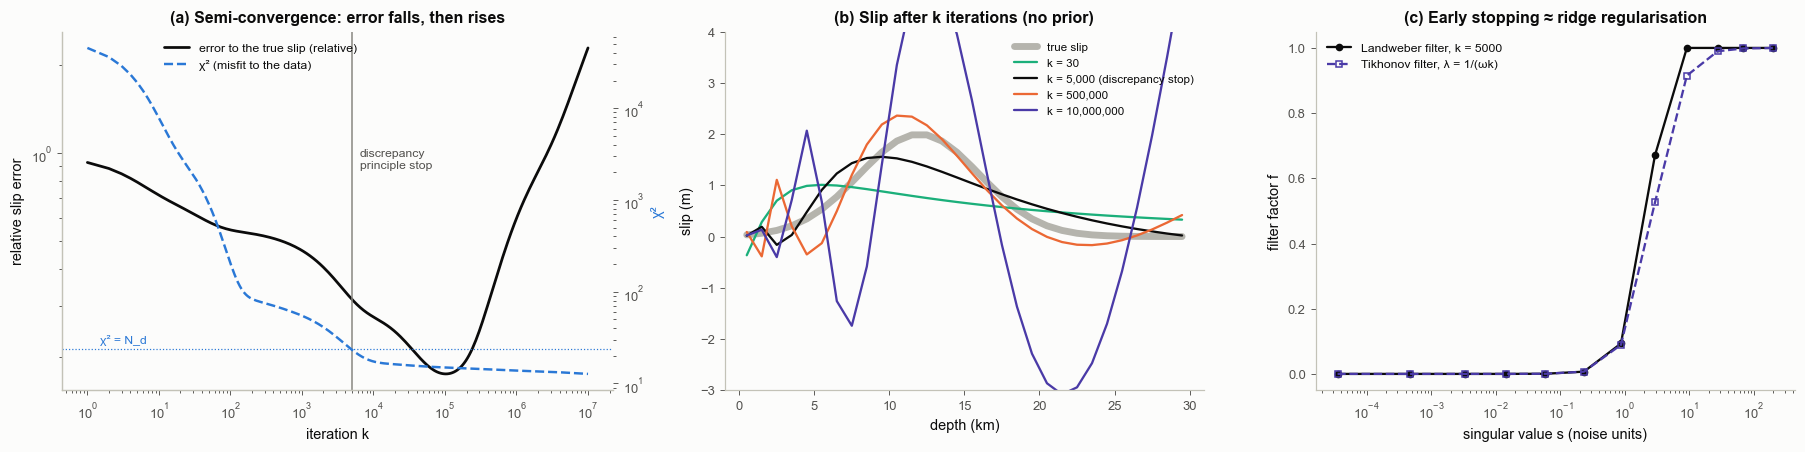

In [22]:
fig, axs = plt.subplots(1, 3, figsize=(16.5, 4.2), gridspec_kw=dict(width_ratios=[1.15, 1, 1]))
ax = axs[0]
ax.loglog(ks, err, color=S.INK, lw=1.8, label="error to the true slip (relative)")
ax2 = ax.twinx()
ax2.loglog(ks, chi2, color=S.BLUE, lw=1.6, ls="--", label="χ² (misfit to the data)")
ax2.axhline(xs8.size, color=S.BLUE, lw=0.8, ls=":")
ax2.text(1.5, xs8.size * 1.15, f"χ² = N_d", fontsize=8, color=S.BLUE)
ax2.set_ylabel("χ²", color=S.BLUE)
ax.axvline(k_disc, color=S.MUTED, lw=1)
ax.text(k_disc * 1.3, 0.62, "discrepancy\nprinciple stop", transform=ax.get_xaxis_transform(), fontsize=8, color=S.INK2)
ax.set_xlabel("iteration k"); ax.set_ylabel("relative slip error")
ax.set_title("(a) Semi-convergence: error falls, then rises")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, fontsize=8, loc="upper center", bbox_to_anchor=(0.36, 1.0))
ax = axs[1]
ax.plot(zc8, s_true8, color="#b5b4ad", lw=4.5, label="true slip", zorder=1)
for k, col in [(30, S.AQUA), (k_disc, S.INK), (100 * k_disc, S.ORANGE), (int(1e7), S.VIOLET)]:
    m_k, _ = landweber(k)
    ax.plot(zc8, m_k, color=col, lw=1.5, label=f"k = {k:,}" + (" (discrepancy stop)" if k == k_disc else ""))
ax.set_xlabel("depth (km)"); ax.set_ylabel("slip (m)")
ax.set_title("(b) Slip after k iterations (no prior)")
ax.legend(fontsize=7.6)
ax.set_ylim(-3, 4)
ax = axs[2]
_, f_k = landweber(k_disc)
ax.semilogx(s8[keep], f_k, "o-", color=S.INK, ms=4, label=f"Landweber filter, k = {k_disc}")
ax.semilogx(s8[keep], s8[keep] ** 2 / (s8[keep] ** 2 + lam_eq), "s--", color=S.VIOLET, ms=4, mfc="none",
            label="Tikhonov filter, λ = 1/(ωk)")
ax.set_xlabel("singular value s (noise units)"); ax.set_ylabel("filter factor f")
ax.set_title("(c) Early stopping ≈ ridge regularisation")
ax.legend(fontsize=8)
fig.tight_layout()
bk.savefig(fig, "2-10_early_stopping")
plt.show()

**How to read it.** (a) The black curve is the error to the true slip: it falls as the well-measured slip
combinations are fitted, reaches a minimum, and rises again as the iterations start fitting noise through tiny singular
values. The blue χ² only falls. The discrepancy stop (grey line) comes earlier than the best possible stop (both
printed), so its slip is smoother than necessary, but it needs no knowledge of the truth and is far from the
late-iteration disaster. (b) Early iterates are smooth; very late ones oscillate with huge amplitude. (c) The two filters
have the same shape: stopping at iteration $k$ acts like a ridge penalty of weight $1/(\omega k)$.

**The image to keep.** The number of iterations is a hidden prior. This is the same effect as the collapse of classic
EKI in notebook 2.24 §5: iterating on the same data is an optimiser that must be stopped, and its result at the stop is
a regularised estimate, not a posterior. Neural-network training uses the same trick (3.02: early stopping on a
validation set, examples held back from the fit to decide when to stop).

## 9. A minimum is not an uncertainty: the Laplace approximation

**In plain words.** An optimiser returns one point. The cheapest way to attach an uncertainty is to fit a Gaussian at
that point using the curvature: sharp curvature, small uncertainty. This works when the posterior is close to a
Gaussian and fails when it is curved, skewed or cut by a bound.

**Precisely.** The Laplace approximation is $p(\mathbf x\mid\mathbf d) \approx \mathcal N(\hat{\mathbf x}, \mathbf H^{-1})$
with $\mathbf H = \nabla^2\mathcal L(\hat{\mathbf x})$ at the MAP $\hat{\mathbf x}$ (2.08). Here it is compared with the
exact posterior on a grid (uniform prior on the box of `SP_BOUNDS`) for the two-parameter problem in two data
situations: all 40 epochs with σ = 2 mm, and only the first 5 days with σ = 5 mm (an early, rough estimate).

In [23]:
def laplace_vs_grid(t_obs, sigma, seed, n=90, window=None):
    T_ = np.asarray(t_obs)
    dd = np.asarray(u2(jnp.asarray(X_TRUE), t_obs=T_)) + sigma * np.random.default_rng(seed).standard_normal(T_.size)
    Lf = lambda x, adj=dfx.RecursiveCheckpointAdjoint(), rt=1e-7: 0.5 * jnp.sum(((u2(x, t_obs=T_, adjoint=adj, rtol=rt) - dd) / sigma) ** 2)
    vg = jax.jit(jax.value_and_grad(Lf))
    best = None
    for s0 in [X_TRUE + 0.1, X0, np.array([0.0, -1.0])]:                  # three starts; keep the lowest
        r_ = minimize(lambda x: tuple(np.asarray(v, float) for v in vg(jnp.asarray(x))), s0, jac=True,
                      method="L-BFGS-B", bounds=list(zip(LO2, HI2)))
        best = r_ if best is None or r_.fun < best.fun else best
    H = np.asarray(jax.hessian(lambda x: Lf(x, dfx.DirectAdjoint()))(jnp.asarray(best.x)))
    C = np.linalg.inv(H)
    if window is None:
        ext = (LO2[0], HI2[0], LO2[1], HI2[1])
    else:
        sd_ = np.sqrt(np.diag(C)); ext = (best.x[0] - window * sd_[0], best.x[0] + window * sd_[0],
                                          best.x[1] - window * sd_[1], best.x[1] + window * sd_[1])
    xa, xv = np.linspace(ext[0], ext[1], n), np.linspace(ext[2], ext[3], n)
    XA, XV = np.meshgrid(xa, xv)
    Lb = jax.jit(jax.vmap(lambda x: Lf(x, rt=1e-6)))
    LGr = np.asarray(Lb(jnp.asarray(np.c_[XA.ravel(), XV.ravel()]))).reshape(XA.shape)
    LGr = np.where(np.isfinite(LGr), LGr, np.inf)                        # a failed solve counts as impossible
    inside = (XA >= LO2[0]) & (XA <= HI2[0]) & (XV >= LO2[1]) & (XV <= HI2[1])
    Pg = np.where(inside, np.exp(-(LGr - LGr.min())), 0.0); Pg /= Pg.sum()
    g = SimpleNamespace(X=XA, Y=XV, P=Pg, levels={})
    pts = np.c_[XA.ravel(), XV.ravel()]
    mean = Pg.ravel() @ pts
    cov = np.cov(pts.T, aweights=Pg.ravel())
    # probability that the Laplace Gaussian assigns to the region outside the prior box
    draws = np.random.default_rng(0).multivariate_normal(best.x, C, 200_000)
    out = np.mean((draws < LO2).any(1) | (draws > HI2).any(1))
    return dict(g=g, xmap=best.x, C=C, mean=mean, cov=cov, ext=ext, out=out, n=T_.size)


LAP = {"all 40 epochs (day 1 to year 1), σ = 2 mm": laplace_vs_grid(A.T_OBS, 0.002, 11, window=5),
       "first 5 days only (11 epochs), σ = 5 mm": laplace_vs_grid(A.T_OBS[A.T_OBS <= 5 / 365.25], 0.005, 12, n=160)}
for name, R in LAP.items():
    sdL, sdG = np.sqrt(np.diag(R["C"])), np.sqrt(np.diag(R["cov"]))
    print(f"{name}  ({R['n']} data)")
    print(f"   MAP {R['xmap']},  exact posterior mean {R['mean']}")
    print(f"   sd (log a_sigma, log v0):  Laplace {sdL},  exact {sdG}")
    print(f"   correlation: Laplace {R['C'][0, 1] / sdL.prod():.3f}, exact {R['cov'][0, 1] / sdG.prod():.3f};  "
          f"Laplace probability outside the prior box: {R['out']:.3f}")

all 40 epochs (day 1 to year 1), σ = 2 mm  (40 data)
   MAP [-0.6921 -3.5061],  exact posterior mean [-0.6921 -3.5062]
   sd (log a_sigma, log v0):  Laplace [0.0047 0.0202],  exact [0.0047 0.0202]
   correlation: Laplace 0.978, exact 0.978;  Laplace probability outside the prior box: 0.000
first 5 days only (11 epochs), σ = 5 mm  (11 data)
   MAP [-1.006  -5.6034],  exact posterior mean [-0.6358 -3.5302]
   sd (log a_sigma, log v0):  Laplace [0.4895 3.8457],  exact [0.3709 1.928 ]
   correlation: Laplace 1.000, exact 0.984;  Laplace probability outside the prior box: 0.441


saved figures/2-10_laplace.png


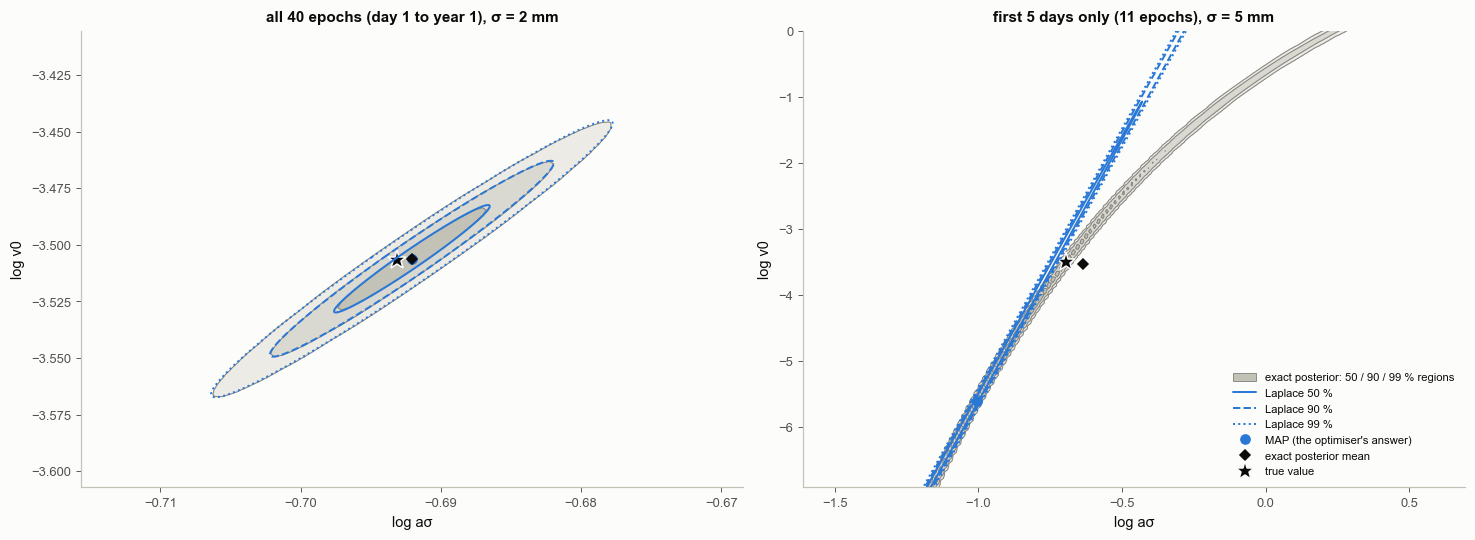

In [24]:
fig, axs = plt.subplots(1, 2, figsize=(13.5, 5))
for ax, (name, R) in zip(axs, LAP.items()):
    BP.density(ax, R["g"])
    for q, ls in [(0.5, "-"), (0.9, "--"), (0.99, ":")]:
        BP.ellipse(ax, R["xmap"], R["C"], nsig=np.sqrt(st.chi2.ppf(q, 2)), color=S.BLUE, lw=1.3, ls=ls,
                   label=f"Laplace {int(q * 100)} %")
    ax.plot(*R["xmap"], "o", color=S.BLUE, ms=6, label="MAP (the optimiser's answer)")
    ax.plot(*R["mean"], "D", color=S.INK, ms=5, label="exact posterior mean")
    ax.plot(*X_TRUE, "*", color=S.INK, ms=13, mec=S.SURFACE, label="true value")
    ax.set_xlim(R["ext"][0], R["ext"][1]); ax.set_ylim(R["ext"][2], R["ext"][3])
    ax.set_xlabel("log aσ"); ax.set_ylabel("log v0")
    ax.set_title(name, fontsize=10)
h, l = axs[0].get_legend_handles_labels()
axs[1].legend(BP.truth_legend() + h, [BP.truth_legend()[0].get_label()] + l, fontsize=7.4, loc="lower right")
fig.tight_layout()
bk.savefig(fig, "2-10_laplace")
plt.show()

**How to read it.** Grey: the exact posterior (50/90/99 % regions). Blue: the Laplace Gaussian built at the MAP.
Left (a year of data): the posterior is a thin, slightly curved ellipse and the Laplace approximation matches it
(compare the printed standard deviations). Right (five days of rougher data): the posterior is a long curved ridge
that runs into the edge of the prior box; the MAP sits at one end of it, the posterior mean is elsewhere, and the
Laplace ellipse is straight and spills outside the box (the printed probability outside). Its standard deviations do
not describe this posterior.

**The image to keep.** An optimiser answers "where is the lowest point?". The posterior answers "where is the
probability?". They agree when the data are strong and the problem is nearly linear (Bernstein-von Mises, 2.05),
which is exactly when you need sampling least. 2.21 replaces the Laplace Gaussian by a fitted one (variational
inference), and notebooks 2.16-2.20 sample the posterior itself.

## 10. Summary

| method | needs per step | strong on | weak on |
|---|---|---|---|
| gradient descent (+ line search) | gradient | simplicity; huge numbers of parameters | narrow or curved valleys (cost grows with the condition number) |
| momentum, Adam | gradient | noisy mini-batch gradients; neural networks | small, ill-conditioned physical problems (slow, step-size tuning) |
| Gauss-Newton | Jacobian (one tangent per parameter, or one adjoint per datum) | least squares with few parameters and good starts | far from the minimum (can overshoot) |
| Levenberg-Marquardt | Jacobian | the same, safer from bad starts | many parameters (Jacobian cost) |
| L-BFGS | gradient | general smooth problems, any size; the default choice | non-smooth losses; bound-heavy problems |
| early-stopped iteration | gradient | cheap regularisation | the stop is a hidden hyperparameter |
| Laplace at the minimum | Hessian | near-Gaussian posteriors | curved, skewed, bounded or multimodal posteriors |

Three facts to carry into the rest of the course:
1. A loss is a likelihood and a prior (sections 1-3); judge every surrogate error in units of the data noise.
2. Speed is about curvature and scaling (sections 4-5); the answer can depend on the start (section 6) and on when you
   stop (section 8).
3. An optimum has no error bar (sections 6 and 9); uncertainty needs the posterior.

**In practice.**
* A weighted RMS misfit and a per-data-set χ² are values of the L2 loss in noise units: they describe the fit at one
  point, not the uncertainty around it (section 9).
* Starting a sampler from an optimiser's answer (a "warm start") is an optimiser handing the sampler a good starting
  point. It affects how fast the chains reach the posterior, not the posterior itself.
* Classic EKI and Landweber iteration are both optimisers that must be stopped (section 8, notebook 2.24 §5). Tempered
  ensemble Kalman inversion avoids the collapse by assimilating fractions of the data that add up to one.
* Limiting the size of each tempering step on a strongly nonlinear forward model is a step-size control in the same
  spirit as the line search of section 4.
* The $(v_0, \Delta\tau)$ trade-off of section 6 can arise in any afterslip model where $v_0$ and the coseismic stress
  change are both free. Whether it matters for a given data set is a question for the posterior correlations, not
  for a single optimum.

Next: [**2.11 · Choosing a prior**](2-11_choosing_a_prior.ipynb).

In [25]:
print(f"notebook run time: {time.time() - T0:.0f} s")

notebook run time: 84 s
